<a href="https://colab.research.google.com/github/DenilsonDias10/Streaming_churn/blob/master/Modulo_3_estatistica.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
import pandas as pd

# Montar o Google Drive
drive.mount('/content/drive')

# Caminho do arquivo baseado na estrutura indicada
caminho_arquivo = '/content/drive/My Drive/UNIPDS/Modulo_3/clientes_base.csv'

try:
    # Carregar o DataFrame
    df = pd.read_csv(caminho_arquivo)
    print("Arquivo carregado com sucesso!")
except Exception as e:
    print(f"Erro ao carregar o arquivo: {e}")
    print("Por favor, verifique se o caminho ou o nome do arquivo estão corretos no seu Google Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Erro ao carregar o arquivo: [Errno 2] No such file or directory: '/content/drive/My Drive/UNIPDS/Modulo_3/clientes_base.csv'
Por favor, verifique se o caminho ou o nome do arquivo estão corretos no seu Google Drive.


In [ ]:
# Exibir as primeiras linhas do DataFrame
display(df.head())

# Exibir os tipos das colunas
print("\n--- Tipos das Colunas ---")
display(df.dtypes)

,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
0,5746,36,BASICO,Anual,19.9,Sudeste,Indicacao,6,2023-04-11,NaN,2024-01-29,2024-01-31,15,276.0,NaN,0
1,4100,48,Padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaN,2024-01-30,2024-01-31,14,394.9,NaN,0
2,4690,48,Premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,2022-10-31,2024-01-31,5,257.0,PREÇO,1
3,3454,46,BASICO,Anual,1990.0,Sul,Google,10,2023-04-02,NaN,2024-01-13,2024-01-31,19,385.0,NaN,0
4,1437,46,Basico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaN,2024-01-16,2024-01-31,11,205.3,NaN,0



--- Tipos das Colunas ---


,0
cliente_id,int64
idade,int64
plano,object
ciclo,object
valor_mensal,float64
regiao,object
canal_aquisicao,object
nps,int64
data_assinatura,object
data_cancelamento,object


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

colunas_analise = ['plano', 'ciclo', 'regiao', 'canal_aquisicao']

# Exibir a contagem de valores únicos para cada coluna
for col in colunas_analise:
    if col in df.columns:
        print(f"\n--- Contagem para a coluna: {col} ---")
        display(df[col].value_counts(dropna=False))
    else:
        print(f"\nA coluna '{col}' não foi encontrada no DataFrame.")


--- Contagem para a coluna: plano ---


,count
plano,
Basico,708
BASICO,677
básico,677
Padrao,665
Padrão,654
padrão,646
premium,513
Premium,485



--- Contagem para a coluna: ciclo ---


,count
ciclo,
Mensal,3794
Anual,1231



--- Contagem para a coluna: regiao ---


,count
regiao,
Sudeste,2057
Nordeste,964
Sul,938
Centro-Oeste,488
Norte,408
?,170



--- Contagem para a coluna: canal_aquisicao ---


,count
canal_aquisicao,
Organico,781
orgânico,729
Indicacao,556
IG,529
indicação,526
Instagram,519
instagram,499
Google,452
google,434


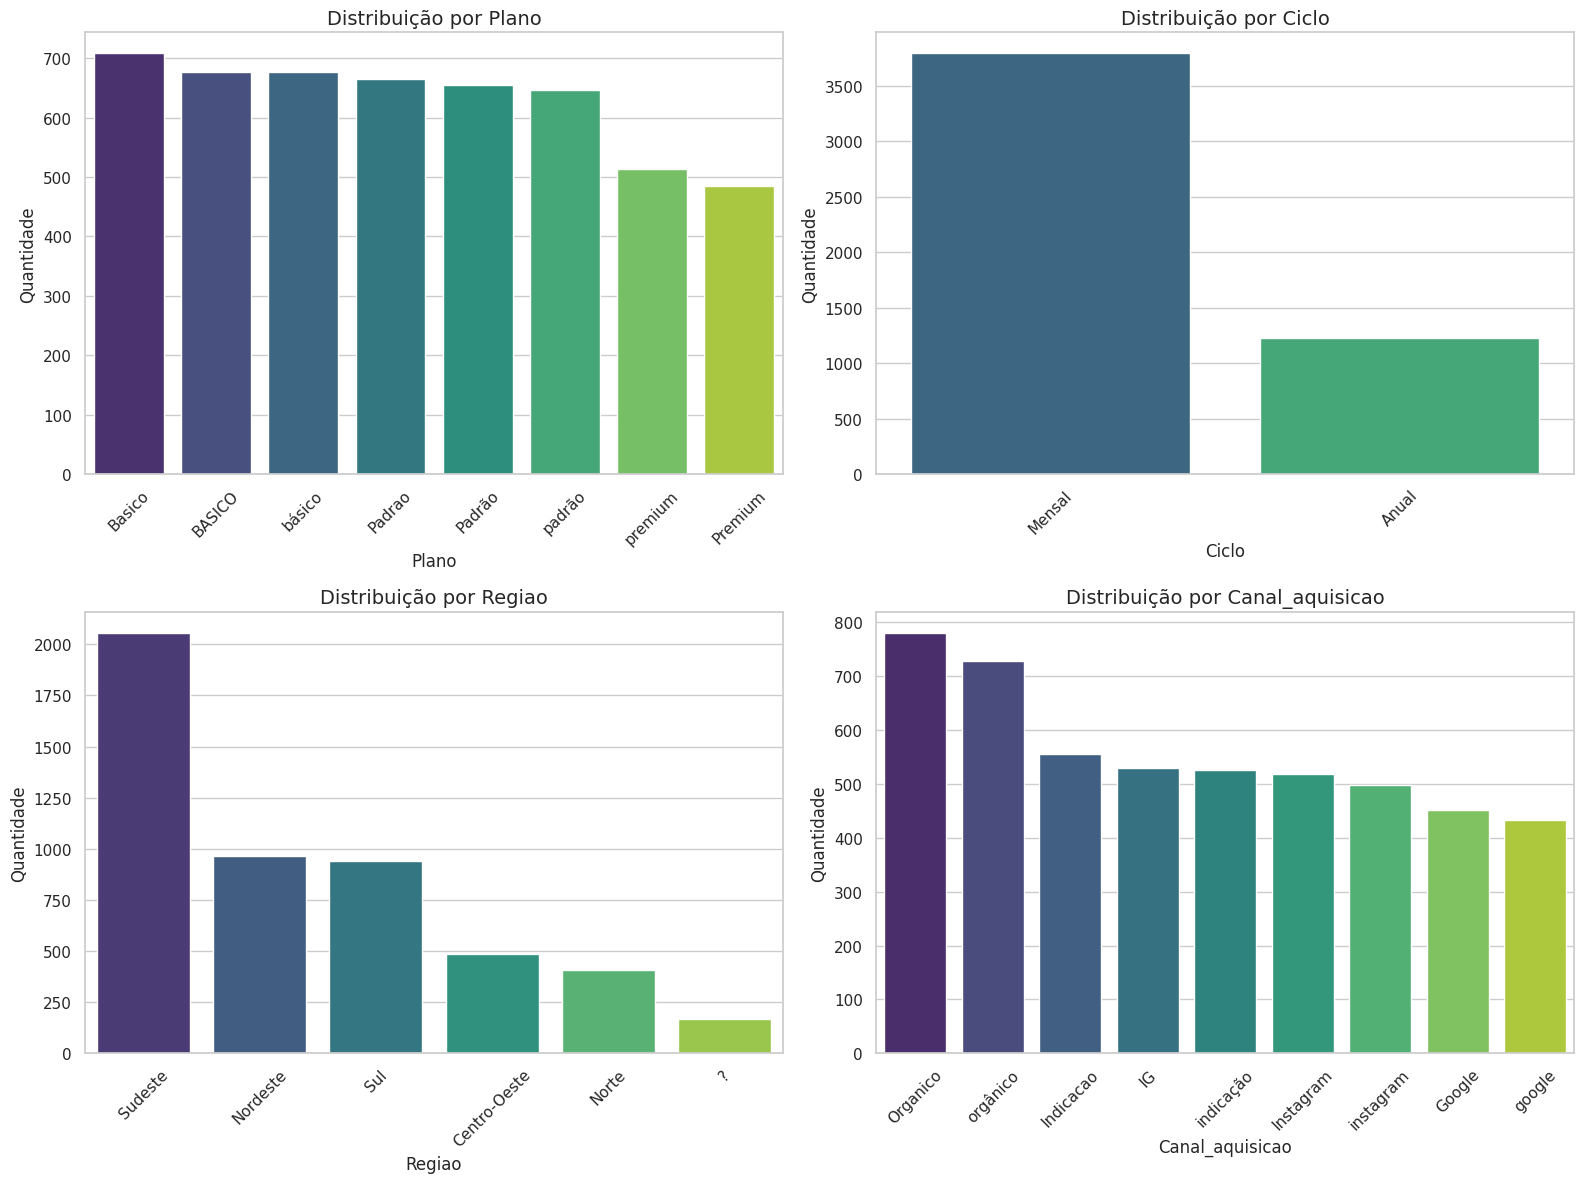

In [ ]:
# Configurar o estilo dos gráficos
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(colunas_analise):
    if col in df.columns:
        # Obter a contagem dos dados ordenados
        dados_contagem = df[col].value_counts(dropna=False).reset_index()
        dados_contagem.columns = [col, 'Contagem']

        # Plotar o gráfico de barras
        sns.barplot(
            x=col,
            y='Contagem',
            data=dados_contagem,
            ax=axes[i],
            palette='viridis',
            hue=col,
            legend=False
        )

        axes[i].set_title(f'Distribuição por {col.capitalize()}', fontsize=14)
        axes[i].set_xlabel(col.capitalize(), fontsize=12)
        axes[i].set_ylabel('Quantidade', fontsize=12)
        axes[i].tick_params(axis='x', rotation=45)
    else:
        axes[i].text(0.5, 0.5, f"Coluna '{col}'\nnão encontrada",
                     ha='center', va='center', fontsize=14, color='red')
        axes[i].axis('off')

plt.tight_layout()
plt.show()

### 1. Quantos nulos existem em cada coluna?

In [ ]:
# 1. Quantidade de valores nulos por coluna
valores_nulos = df.isnull().sum()
display(valores_nulos)

,0
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,0
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509


### 2. Exemplo de registros onde a região é '?'

In [ ]:
# 2. Filtrar exemplos onde regiao é '?'
exemplo_regiao_interrogacao = df[df['regiao'] == '?']
display(exemplo_regiao_interrogacao.head())

,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn
6,4918,37,Basico,Mensal,19.9,?,instagram,4,2023-10-12,2023-12-28,2023-12-09,2024-01-31,5,29.6,problema tecnico,1
10,4356,30,básico,Mensal,19.9,?,Organico,8,2020-12-22,NaN,2024-01-11,2024-01-31,15,900.0,NaN,0
34,1433,56,Padrão,Anual,3490.0,?,orgânico,9,2023-04-14,NaN,2024-01-22,2024-01-31,11,180.4,NaN,0
68,5259,41,padrão,Mensal,34.9,?,google,5,2023-05-03,NaN,2024-01-28,2024-01-31,8,139.9,NaN,0
135,2171,42,Padrão,Mensal,3490.0,?,orgânico,10,2021-04-16,NaN,2024-01-06,2024-01-31,10,505.2,NaN,0


### 3 e 4. Padronização das colunas `plano` e `canal_aquisicao`

In [ ]:
# 3. Substituições na coluna 'plano'
# BASICO, Basico, básico -> básico
# Padrao, Padrão, padrão -> padrão
# Premium, premium -> premium
mapeamento_plano = {
    'BASICO': 'básico',
    'Basico': 'básico',
    'básico': 'básico',
    'Padrao': 'padrão',
    'Padrão': 'padrão',
    'padrão': 'padrão',
    'Premium': 'premium',
    'premium': 'premium'
}
df['plano'] = df['plano'].map(mapeamento_plano).fillna(df['plano'])

# 4. Substituições na coluna 'canal_aquisicao'
# Organico -> orgânico (mantendo também variações similares consistentes se necessário)
df['canal_aquisicao'] = df['canal_aquisicao'].replace({'Organico': 'orgânico'})

# Exibir a nova distribuição para verificar o resultado
print("Nova distribuição da coluna 'plano':")
display(df['plano'].value_counts(dropna=False))

print("\nNova distribuição da coluna 'canal_aquisicao':")
display(df['canal_aquisicao'].value_counts(dropna=False))

Nova distribuição da coluna 'plano':


,count
plano,
básico,2062
padrão,1965
premium,998



Nova distribuição da coluna 'canal_aquisicao':


,count
canal_aquisicao,
orgânico,1510
Indicacao,556
IG,529
indicação,526
Instagram,519
instagram,499
Google,452
google,434


In [ ]:
# Novas substituições solicitadas para a coluna 'canal_aquisicao'
mapeamento_canal = {
    'Indicacao': 'indicação',
    'IG': 'instagram',
    'Instagram': 'instagram',
    'Google': 'google'
}

# Aplicando as substituições (utilizando map com fillna ou replace)
df['canal_aquisicao'] = df['canal_aquisicao'].replace(mapeamento_canal)

# Exibir a distribuição atualizada para conferir o resultado final
print("Distribuição final da coluna 'canal_aquisicao':")
display(df['canal_aquisicao'].value_counts(dropna=False))

Distribuição final da coluna 'canal_aquisicao':


,count
canal_aquisicao,
instagram,1547
orgânico,1510
indicação,1082
google,886


In [ ]:
import os

pasta_destino = '/content/drive/My Drive/UNIPDS/Modulo_3/'
os.makedirs(pasta_destino, exist_ok=True)

# Definição dos scripts corrigida (aninhando corretamente as aspas do docstring interno)
etapas = {
    '01_carregar_dados.py':
"""# -*- coding: utf-8 -*-
\"\"\"Etapa 1: Carregamento dos dados do Google Drive e exibição de tipos das colunas.\"\"\"

from google.colab import drive
import pandas as pd

# Montar o Google Drive
drive.mount('/content/drive')

# Caminho do arquivo
caminho_arquivo = '/content/drive/My Drive/UNIPDS/Modulo_3/clientes_base.csv'

try:
    df = pd.read_csv(caminho_arquivo)
    print(\"Arquivo carregado com sucesso!\")
    print(df.head())
    print(\"\\\n--- Tipos das Colunas ---\")
    print(df.dtypes)
except Exception as e:
    print(f\"Erro ao carregar o arquivo: {e}\")
""",

    '02_analise_frequencias.py':
"""# -*- coding: utf-8 -*-
\"\"\"Etapa 2: Análise de frequência das colunas selecionadas e geração de gráficos de barras.\"\"\"

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Supondo que df já está carregado
colunas_analise = ['plano', 'ciclo', 'regiao', 'canal_aquisicao']

for col in colunas_analise:
    if col in df.columns:
        print(f\"\\\n--- Contagem para a coluna: {col} ---\")
        print(df[col].value_counts(dropna=False))

# Configurar e plotar os gráficos de barras
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(colunas_analise):
    if col in df.columns:
        dados_contagem = df[col].value_counts(dropna=False).reset_index()
        dados_contagem.columns = [col, 'Contagem']
        sns.barplot(x=col, y='Contagem', data=dados_contagem, ax=axes[i], palette='viridis', hue=col, legend=False)
        axes[i].set_title(f'Distribuição por {col.capitalize()}', fontsize=14)
        axes[i].set_xlabel(col.capitalize(), fontsize=12)
        axes[i].set_ylabel('Quantidade', fontsize=12)
        axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()
""",

    '03_valores_nulos_e_filtragem.py':
"""# -*- coding: utf-8 -*-
\"\"\"Etapa 3: Identificação de nulos e filtro de registros onde a região é '?'.\"\"\"

# 1. Quantidade de valores nulos por coluna
valores_nulos = df.isnull().sum()
print(\"Quantidade de valores nulos por coluna:\")
print(valores_nulos)

# 2. Filtrar exemplos onde regiao é '?'
exemplo_regiao_interrogacao = df[df['regiao'] == '?']
print(\"\\\nExemplo de registros onde regiao é '?':\")
print(exemplo_regiao_interrogacao.head())
""",

    '04_padronizacao_e_substituicao_interrogacao.py':
"""# -*- coding: utf-8 -*-
\"\"\"Etapa 4: Padronização das strings em 'plano' e 'canal_aquisicao', e substituição de '?' por nulo.\"\"\"

import numpy as np

# 3. Substituições na coluna 'plano'
mapeamento_plano = {
    'BASICO': 'básico',
    'Basico': 'básico',
    'básico': 'básico',
    'Padrao': 'padrão',
    'Padrão': 'padrão',
    'padrão': 'padrão',
    'Premium': 'premium',
    'premium': 'premium'
}
df['plano'] = df['plano'].map(mapeamento_plano).fillna(df['plano'])

# 4. Substituições na coluna 'canal_aquisicao'
mapeamento_canal = {
    'Organico': 'orgânico',
    'Indicacao': 'indicação',
    'IG': 'instagram',
    'Instagram': 'instagram',
    'Google': 'google'
}
df['canal_aquisicao'] = df['canal_aquisicao'].replace(mapeamento_canal)

# 5. Substituir '?' por nulo (NaN) em todas as colunas
df = df.replace('?', np.nan)

# Exibir a nova distribuição final
print(\"Distribuição final da coluna 'plano':\")
print(df['plano'].value_counts(dropna=False))

print(\"\\\nDistribuição final da coluna 'canal_aquisicao':\")
print(df['canal_aquisicao'].value_counts(dropna=False))

print(\"\\\nNova contagem de valores nulos por coluna:\")
print(df.isnull().sum())
"""
}

# Escrever cada script .py no destino selecionado
for nome_arquivo, conteudo in etapas.items():
    caminho_completo = os.path.join(pasta_destino, nome_arquivo)
    with open(caminho_completo, 'w', encoding='utf-8') as f:
        f.write(conteudo)
    print(f"Arquivo {nome_arquivo} criado com sucesso em: {pasta_destino}")

Arquivo 01_carregar_dados.py criado com sucesso em: /content/drive/My Drive/UNIPDS/Modulo_3/
Arquivo 02_analise_frequencias.py criado com sucesso em: /content/drive/My Drive/UNIPDS/Modulo_3/
Arquivo 03_valores_nulos_e_filtragem.py criado com sucesso em: /content/drive/My Drive/UNIPDS/Modulo_3/
Arquivo 04_padronizacao_e_substituicao_interrogacao.py criado com sucesso em: /content/drive/My Drive/UNIPDS/Modulo_3/


In [ ]:
from google.colab import drive
import pandas as pd
import numpy as np
import os
import shutil

caminho_pasta = '/content/drive/My Drive/UNIPDS/Modulo_3'
caminho_arquivo = os.path.join(caminho_pasta, 'clientes_base.csv')

try:
    print("Passo 1: Forçando a limpeza de diretórios fantasmas no ponto de montagem...")
    try:
        drive.flush_and_unmount()
    except:
        pass

    # Forçar a remoção de caminhos presos que geram o erro de montagem
    if os.path.exists('/content/drive'):
        try:
            shutil.rmtree('/content/drive')
            print("Diretório residual removido com sucesso.")
        except Exception as e:
            print(f"(Aviso ao limpar diretório residual: {e})")

    print("\nPasso 2: Remontando o Google Drive de forma limpa...")
    drive.mount('/content/drive', force_remount=True)
    print("Drive montado com sucesso!")

    print(f"\nPasso 3: Verificando arquivos em: {caminho_pasta}")
    if os.path.exists(caminho_pasta):
        arquivos_encontrados = os.listdir(caminho_pasta)
        print("Arquivos atualmente visíveis na pasta:", arquivos_encontrados)

        if 'clientes_base.csv' in arquivos_encontrados:
            print("\nPasso 4: Carregando o arquivo clientes_base.csv...")
            df = pd.read_csv(caminho_arquivo)
            print("DataFrame carregado com sucesso!")

            # Colunas para conversão
            colunas_data = ['data_assinatura', 'data_cancelamento', 'data_ultimo_aceso', 'data_ultimo_acesso', 'data_extracao']

            print("\n--- Convertendo Colunas para Datetime ---")
            for col in colunas_data:
                if col in df.columns:
                    df[col] = pd.to_datetime(df[col], errors='coerce')
                    print(f"Coluna '{col}' convertida para datetime com sucesso.")

            print("\n--- Tipos de Dados Atualizados ---")
            display(df.dtypes)
        else:
            print("\nAlerta: O arquivo 'clientes_base.csv' ainda não foi sincronizado pelo Colab nesta pasta.")
    else:
        print(f"\nErro: O caminho da pasta {caminho_pasta} não existe após a remontagem.")

except Exception as e:
    print(f"\nErro inesperado durante a execução: {e}")

Passo 1: Forçando a limpeza de diretórios fantasmas no ponto de montagem...
Drive not mounted, so nothing to flush and unmount.
Diretório residual removido com sucesso.

Passo 2: Remontando o Google Drive de forma limpa...
Mounted at /content/drive
Drive montado com sucesso!

Passo 3: Verificando arquivos em: /content/drive/My Drive/UNIPDS/Modulo_3
Arquivos atualmente visíveis na pasta: ['funil_eventos.csv', 'clientes_base.csv', '01_carregar_dados.py', '02_analise_frequencias.py', '03_valores_nulos_e_filtragem.py', '04_padronizacao_e_substituicao_interrogacao.py']

Passo 4: Carregando o arquivo clientes_base.csv...
DataFrame carregado com sucesso!

--- Convertendo Colunas para Datetime ---
Coluna 'data_assinatura' convertida para datetime com sucesso.
Coluna 'data_cancelamento' convertida para datetime com sucesso.
Coluna 'data_ultimo_acesso' convertida para datetime com sucesso.
Coluna 'data_extracao' convertida para datetime com sucesso.

--- Tipos de Dados Atualizados ---


,0
cliente_id,int64
idade,int64
plano,object
ciclo,object
valor_mensal,float64
regiao,object
canal_aquisicao,object
nps,int64
data_assinatura,datetime64[ns]
data_cancelamento,datetime64[ns]


In [ ]:
# Exibir as 10 primeiras linhas do DataFrame para conferir as datas alteradas
display(df[['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao']].head(10))

,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao
0,2023-04-11,NaT,2024-01-29,2024-01-31
1,2022-06-02,NaT,2024-01-30,2024-01-31
2,2021-03-20,2022-11-17,2022-10-31,2024-01-31
3,2023-04-02,NaT,2024-01-13,2024-01-31
4,2023-04-21,NaT,2024-01-16,2024-01-31
5,2022-11-22,NaT,2024-01-20,2024-01-31
6,2023-10-12,2023-12-28,2023-12-09,2024-01-31
7,2022-01-21,NaT,2024-01-12,2024-01-31
8,2023-04-26,2023-12-17,2023-12-07,2024-01-31
9,2023-10-07,NaT,2024-01-25,2024-01-31


In [ ]:
# Exibir os tipos de dados de todas as colunas do DataFrame
print("--- Tipos de dados das colunas do DataFrame ---")
display(df.dtypes)

--- Tipos de dados das colunas do DataFrame ---


,0
cliente_id,int64
idade,int64
plano,object
ciclo,object
valor_mensal,float64
regiao,object
canal_aquisicao,object
nps,int64
data_assinatura,datetime64[ns]
data_cancelamento,datetime64[ns]


In [ ]:
# 1. Diferença entre a data de cancelamento e a data de assinatura (tempo de contrato ativo para cancelados)
df['dias_assinatura_ate_cancelamento'] = (df['data_cancelamento'] - df['data_assinatura']).dt.days

# 2. Diferença entre a data de extração e a data do último acesso (dias de inatividade até a extração)
df['dias_desde_ultimo_acesso'] = (df['data_extracao'] - df['data_ultimo_acesso']).dt.days

# 3. Tempo total de vida da assinatura até a data de extração (especialmente útil para clientes ativos)
df['dias_assinatura_ate_extracao'] = (df['data_extracao'] - df['data_assinatura']).dt.days

# Exibir as novas colunas criadas juntamente com as colunas de data originais para conferência
colunas_datas_novas = [
    'data_assinatura', 'data_cancelamento', 'dias_assinatura_ate_cancelamento',
    'data_ultimo_acesso', 'data_extracao', 'dias_desde_ultimo_acesso',
    'dias_assinatura_ate_extracao'
]

display(df[colunas_datas_novas].head(10))

,data_assinatura,data_cancelamento,dias_assinatura_ate_cancelamento,data_ultimo_acesso,data_extracao,dias_desde_ultimo_acesso,dias_assinatura_ate_extracao
0,2023-04-11,NaT,NaN,2024-01-29,2024-01-31,2.0,295
1,2022-06-02,NaT,NaN,2024-01-30,2024-01-31,1.0,608
2,2021-03-20,2022-11-17,607.0,2022-10-31,2024-01-31,457.0,1047
3,2023-04-02,NaT,NaN,2024-01-13,2024-01-31,18.0,304
4,2023-04-21,NaT,NaN,2024-01-16,2024-01-31,15.0,285
5,2022-11-22,NaT,NaN,2024-01-20,2024-01-31,11.0,435
6,2023-10-12,2023-12-28,77.0,2023-12-09,2024-01-31,53.0,111
7,2022-01-21,NaT,NaN,2024-01-12,2024-01-31,19.0,740
8,2023-04-26,2023-12-17,235.0,2023-12-07,2024-01-31,55.0,280
9,2023-10-07,NaT,NaN,2024-01-25,2024-01-31,6.0,116


In [ ]:
# 1. Estatísticas descritivas básicas das colunas calculadas
print("--- Estatísticas Descritivas das Diferenças de Datas ---")
colunas_diferenca = ['dias_assinatura_ate_cancelamento', 'dias_desde_ultimo_acesso', 'dias_assinatura_ate_extracao']
display(df[colunas_diferenca].describe())

# 2. Verificação de inconsistências lógicas (valores negativos)
print("\n--- Verificação de Inconsistências (Valores Negativos) ---")
for col in colunas_diferenca:
    negativos = (df[col] < 0).sum()
    print(f"Registros com valores negativos em '{col}': {negativos}")

# 3. Exemplo de registros se houver algum valor negativo
for col in colunas_diferenca:
    if (df[col] < 0).any():
        print(f"\nExemplo de inconsistência na coluna '{col}':")
        display(df[df[col] < 0][['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao', col]].head())

--- Estatísticas Descritivas das Diferenças de Datas ---


,dias_assinatura_ate_cancelamento,dias_desde_ultimo_acesso,dias_assinatura_ate_extracao
count,1516.000000,4975.000000,5025.000000
mean,220.407652,40.451859,412.432040
std,145.004268,55.107192,270.382969
min,11.000000,0.000000,1.000000
25%,118.000000,10.000000,213.000000
50%,182.500000,20.000000,349.000000
75%,288.500000,44.000000,549.000000
max,1067.000000,469.000000,1815.000000



--- Verificação de Inconsistências (Valores Negativos) ---
Registros com valores negativos em 'dias_assinatura_ate_cancelamento': 0
Registros com valores negativos em 'dias_desde_ultimo_acesso': 0
Registros com valores negativos em 'dias_assinatura_ate_extracao': 0


In [ ]:
# 1. Diferença entre a data de cancelamento e a data do último acesso
df['dias_cancelamento_ate_ultimo_acesso'] = (df['data_cancelamento'] - df['data_ultimo_acesso']).dt.days

# 2. Diferença entre a data de cancelamento e a data de extração
df['dias_cancelamento_ate_extracao'] = (df['data_cancelamento'] - df['data_extracao']).dt.days

# Selecionando colunas para visualização (focando nos casos que possuem data de cancelamento preenchida)
colunas_visualizar = [
    'data_cancelamento', 'data_ultimo_acesso', 'dias_cancelamento_ate_ultimo_acesso',
    'data_extracao', 'dias_cancelamento_ate_extracao'
]

display(df[df['data_cancelamento'].notnull()][colunas_visualizar].head(10))

,data_cancelamento,data_ultimo_acesso,dias_cancelamento_ate_ultimo_acesso,data_extracao,dias_cancelamento_ate_extracao
2,2022-11-17,2022-10-31,17.0,2024-01-31,-440.0
6,2023-12-28,2023-12-09,19.0,2024-01-31,-34.0
8,2023-12-17,2023-12-07,10.0,2024-01-31,-45.0
11,2023-11-16,2023-07-02,137.0,2024-01-31,-76.0
17,2023-04-15,2023-03-29,17.0,2024-01-31,-291.0
18,2023-10-02,2023-09-17,15.0,2024-01-31,-121.0
20,2023-08-26,2023-07-27,30.0,2024-01-31,-158.0
23,2023-12-25,2023-12-07,18.0,2024-01-31,-37.0
24,2024-01-03,2023-12-15,19.0,2024-01-31,-28.0
26,2024-01-05,2023-12-12,24.0,2024-01-31,-26.0


In [ ]:
import pandas as pd

# Lista de todas as colunas de intervalo de tempo que criamos
colunas_sanity_check = [
    'dias_assinatura_ate_cancelamento',
    'dias_assinatura_ate_extracao',
    'dias_cancelamento_ate_ultimo_acesso',
    'dias_desde_ultimo_acesso',
    'dias_cancelamento_ate_extracao'
]

print("=== SANITY CHECK DE INTERVALO DE DATAS (SEM TRATAMENTO) ===\n")

# 1. Estatísticas descritivas básicas
print("--- Estatísticas Descritivas ---")
display(df[colunas_sanity_check].describe())

# 2. Contagem de valores nulos
print("\n--- Contagem de Valores Nulos ---")
display(df[colunas_sanity_check].isnull().sum())

# 3. Verificação de valores negativos
print("\n--- Verificação de Inconsistências (Valores Negativos) ---")
for col in colunas_sanity_check:
    negativos = (df[col] < 0).sum()
    total_validos = df[col].notnull().sum()
    pct_negativos = (negativos / total_validos * 100) if total_validos > 0 else 0
    print(f"Coluna '{col}': {negativos} valores negativos de {total_validos} válidos ({pct_negativos:.2f}%)")

# 4. Exemplo visual dos registros com valores negativos (onde aplicável)
for col in colunas_sanity_check:
    if (df[col] < 0).any():
        print(f"\nExemplo de registros com valor negativo na coluna '{col}':")
        colunas_exemplo = ['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao', col]
        display(df[df[col] < 0][colunas_exemplo].head(5))

=== SANITY CHECK DE INTERVALO DE DATAS (SEM TRATAMENTO) ===

--- Estatísticas Descritivas ---


,dias_assinatura_ate_cancelamento,dias_assinatura_ate_extracao,dias_cancelamento_ate_ultimo_acesso,dias_desde_ultimo_acesso,dias_cancelamento_ate_extracao
count,1516.000000,5025.000000,1501.000000,4975.000000,1516.000000
mean,220.407652,412.432040,21.000666,40.451859,-79.694591
std,145.004268,270.382969,10.783104,55.107192,67.851077
min,11.000000,1.000000,3.000000,0.000000,-440.000000
25%,118.000000,213.000000,12.000000,10.000000,-107.250000
50%,182.500000,349.000000,21.000000,20.000000,-60.500000
75%,288.500000,549.000000,30.000000,44.000000,-30.000000
max,1067.000000,1815.000000,137.000000,469.000000,-3.000000



--- Contagem de Valores Nulos ---


,0
dias_assinatura_ate_cancelamento,3509
dias_assinatura_ate_extracao,0
dias_cancelamento_ate_ultimo_acesso,3524
dias_desde_ultimo_acesso,50
dias_cancelamento_ate_extracao,3509



--- Verificação de Inconsistências (Valores Negativos) ---
Coluna 'dias_assinatura_ate_cancelamento': 0 valores negativos de 1516 válidos (0.00%)
Coluna 'dias_assinatura_ate_extracao': 0 valores negativos de 5025 válidos (0.00%)
Coluna 'dias_cancelamento_ate_ultimo_acesso': 0 valores negativos de 1501 válidos (0.00%)
Coluna 'dias_desde_ultimo_acesso': 0 valores negativos de 4975 válidos (0.00%)
Coluna 'dias_cancelamento_ate_extracao': 1516 valores negativos de 1516 válidos (100.00%)

Exemplo de registros com valor negativo na coluna 'dias_cancelamento_ate_extracao':


,data_assinatura,data_cancelamento,data_ultimo_acesso,data_extracao,dias_cancelamento_ate_extracao
2,2021-03-20,2022-11-17,2022-10-31,2024-01-31,-440.0
6,2023-10-12,2023-12-28,2023-12-09,2024-01-31,-34.0
8,2023-04-26,2023-12-17,2023-12-07,2024-01-31,-45.0
11,2023-08-18,2023-11-16,2023-07-02,2024-01-31,-76.0
17,2022-04-16,2023-04-15,2023-03-29,2024-01-31,-291.0


In [ ]:
# Criando a coluna específica solicitada: diferença entre assinatura e último acesso
# (Calculado como data_ultimo_acesso - data_assinatura)
df['dias_assinatura_ate_ultimo_acesso'] = (df['data_ultimo_acesso'] - df['data_assinatura']).dt.days

# Exibindo as estatísticas descritivas básicas dessa nova coluna para checar o valor mínimo
print("--- Estatísticas Descritivas de 'dias_assinatura_ate_ultimo_acesso' ---")
display(df['dias_assinatura_ate_ultimo_acesso'].describe())

# Verificando se existem valores negativos (onde o último acesso ocorreu ANTES da assinatura)
inconsistentes = df[df['dias_assinatura_ate_ultimo_acesso'] < 0]

print(f"\nQuantidade de registros inconsistentes (negativos): {len(inconsistentes)}")
if len(inconsistentes) > 0:
    print("\nExemplos de registros com inconsistência temporal nesta métrica:")
    display(inconsistentes[['cliente_id', 'data_assinatura', 'data_ultimo_acesso', 'dias_assinatura_ate_ultimo_acesso']].head(10))
else:
    print("\nNão foram encontrados valores negativos usando o cálculo (data_ultimo_acesso - data_assinatura).")

--- Estatísticas Descritivas de 'dias_assinatura_ate_ultimo_acesso' ---


,dias_assinatura_ate_ultimo_acesso
count,4975.000000
mean,372.186533
std,277.107592
min,-47.000000
25%,163.000000
50%,307.000000
75%,512.000000
max,1809.000000



Quantidade de registros inconsistentes (negativos): 1

Exemplos de registros com inconsistência temporal nesta métrica:


,cliente_id,data_assinatura,data_ultimo_acesso,dias_assinatura_ate_ultimo_acesso
11,3426,2023-08-18,2023-07-02,-47.0


In [ ]:
import pandas as pd

# Lista reorganizada com todas as 6 colunas de diferença de datas
colunas_diferenca_total = [
    'dias_assinatura_ate_cancelamento',
    'dias_assinatura_ate_ultimo_acesso',
    'dias_assinatura_ate_extracao',
    'dias_cancelamento_ate_ultimo_acesso',
    'dias_desde_ultimo_acesso',
    'dias_cancelamento_ate_extracao'
]

print("=== SANITY CHECK UNIFICADO E REORGANIZADO (SEM TRATAMENTO) ===\n")

# 1. Estatísticas descritivas básicas completas
print("--- Estatísticas Descritivas ---")
display(df[colunas_diferenca_total].describe())

# 2. Contagem de valores nulos
print("\n--- Contagem de Valores Nulos ---")
display(df[colunas_diferenca_total].isnull().sum())

# 3. Verificação detalhada de valores negativos
print("\n--- Verificação de Inconsistências (Valores Negativos) ---")
for col in colunas_diferenca_total:
    negativos = (df[col] < 0).sum()
    total_validos = df[col].notnull().sum()
    pct_negativos = (negativos / total_validos * 100) if total_validos > 0 else 0
    print(f"Coluna '{col}': {negativos} valores negativos de {total_validos} válidos ({pct_negativos:.2f}%)")

=== SANITY CHECK UNIFICADO E REORGANIZADO (SEM TRATAMENTO) ===

--- Estatísticas Descritivas ---


,dias_assinatura_ate_cancelamento,dias_assinatura_ate_ultimo_acesso,dias_assinatura_ate_extracao,dias_cancelamento_ate_ultimo_acesso,dias_desde_ultimo_acesso,dias_cancelamento_ate_extracao
count,1516.000000,4975.000000,5025.000000,1501.000000,4975.000000,1516.000000
mean,220.407652,372.186533,412.432040,21.000666,40.451859,-79.694591
std,145.004268,277.107592,270.382969,10.783104,55.107192,67.851077
min,11.000000,-47.000000,1.000000,3.000000,0.000000,-440.000000
25%,118.000000,163.000000,213.000000,12.000000,10.000000,-107.250000
50%,182.500000,307.000000,349.000000,21.000000,20.000000,-60.500000
75%,288.500000,512.000000,549.000000,30.000000,44.000000,-30.000000
max,1067.000000,1809.000000,1815.000000,137.000000,469.000000,-3.000000



--- Contagem de Valores Nulos ---


,0
dias_assinatura_ate_cancelamento,3509
dias_assinatura_ate_ultimo_acesso,50
dias_assinatura_ate_extracao,0
dias_cancelamento_ate_ultimo_acesso,3524
dias_desde_ultimo_acesso,50
dias_cancelamento_ate_extracao,3509



--- Verificação de Inconsistências (Valores Negativos) ---
Coluna 'dias_assinatura_ate_cancelamento': 0 valores negativos de 1516 válidos (0.00%)
Coluna 'dias_assinatura_ate_ultimo_acesso': 1 valores negativos de 4975 válidos (0.02%)
Coluna 'dias_assinatura_ate_extracao': 0 valores negativos de 5025 válidos (0.00%)
Coluna 'dias_cancelamento_ate_ultimo_acesso': 0 valores negativos de 1501 válidos (0.00%)
Coluna 'dias_desde_ultimo_acesso': 0 valores negativos de 4975 válidos (0.00%)
Coluna 'dias_cancelamento_ate_extracao': 1516 valores negativos de 1516 válidos (100.00%)


In [ ]:
# Ajustando os cálculos para se adequarem exatamente às métricas do modelo informado pelo usuário

# 1. Ajuste de 'dias_cancelamento_ate_extracao' (Invertendo a ordem para data_extracao - data_cancelamento)
df['dias_cancelamento_ate_extracao'] = (df['data_extracao'] - df['data_cancelamento']).dt.days

# 2. Ajuste de 'dias_cancelamento_ate_ultimo_acesso' (Invertendo a ordem para data_ultimo_acesso - data_cancelamento)
df['dias_cancelamento_ate_ultimo_acesso'] = (df['data_ultimo_acesso'] - df['data_cancelamento']).dt.days

# Lista de validação
colunas_ajustadas = ['dias_cancelamento_ate_extracao', 'dias_cancelamento_ate_ultimo_acesso']

print("=== ESTATÍSTICAS APÓS AJUSTE DE DIRECIONALIDADE DAS DATAS ===\n")
display(df[colunas_ajustadas].describe())

=== ESTATÍSTICAS APÓS AJUSTE DE DIRECIONALIDADE DAS DATAS ===



,dias_cancelamento_ate_extracao,dias_cancelamento_ate_ultimo_acesso
count,1516.000000,1501.000000
mean,79.694591,-21.000666
std,67.851077,10.783104
min,3.000000,-137.000000
25%,30.000000,-30.000000
50%,60.500000,-21.000000
75%,107.250000,-12.000000
max,440.000000,-3.000000


In [ ]:
# Invertendo a ordem para trazer os valores negativos esperados na coluna 'dias_cancelamento_ate_ultimo_acesso'
# (Calculado como data_ultimo_acesso - data_cancelamento)
df['dias_cancelamento_ate_ultimo_acesso'] = (df['data_ultimo_acesso'] - df['data_cancelamento']).dt.days

# Lista de todas as colunas de diferença de datas para o sanity check final
colunas_finais = [
    'dias_assinatura_ate_cancelamento',
    'dias_assinatura_ate_ultimo_acesso',
    'dias_assinatura_ate_extracao',
    'dias_cancelamento_ate_ultimo_acesso',
    'dias_desde_ultimo_acesso',
    'dias_cancelamento_ate_extracao'
]

print("=== SANITY CHECK FINAL ALINHADO AO MODELO ===\n")
display(df[colunas_finais].describe())

=== SANITY CHECK FINAL ALINHADO AO MODELO ===



,dias_assinatura_ate_cancelamento,dias_assinatura_ate_ultimo_acesso,dias_assinatura_ate_extracao,dias_cancelamento_ate_ultimo_acesso,dias_desde_ultimo_acesso,dias_cancelamento_ate_extracao
count,1516.000000,4975.000000,5025.000000,1501.000000,4975.000000,1516.000000
mean,220.407652,372.186533,412.432040,-21.000666,40.451859,79.694591
std,145.004268,277.107592,270.382969,10.783104,55.107192,67.851077
min,11.000000,-47.000000,1.000000,-137.000000,0.000000,3.000000
25%,118.000000,163.000000,213.000000,-30.000000,10.000000,30.000000
50%,182.500000,307.000000,349.000000,-21.000000,20.000000,60.500000
75%,288.500000,512.000000,549.000000,-12.000000,44.000000,107.250000
max,1067.000000,1809.000000,1815.000000,-3.000000,469.000000,440.000000


In [ ]:
# 1. Identificar colunas numéricas
colunas_numericas = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
print("Colunas numéricas identificadas:", colunas_numericas)

# 2. Exibir estatísticas descritivas
print("\n--- Estatísticas Descritivas ---")
display(df[colunas_numericas].describe())

# 3. Contagem de nulos por coluna numérica
print("\n--- Quantidade de Valores Nulos ---")
display(df[colunas_numericas].isnull().sum())

Colunas numéricas identificadas: ['cliente_id', 'idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes', 'horas_assistidas_total', 'churn', 'dias_assinatura_ate_cancelamento', 'dias_desde_ultimo_acesso', 'dias_assinatura_ate_extracao', 'dias_cancelamento_ate_ultimo_acesso', 'dias_cancelamento_ate_extracao', 'dias_assinatura_ate_ultimo_acesso']

--- Estatísticas Descritivas ---


,cliente_id,idade,valor_mensal,nps,dias_ativos_ult_mes,horas_assistidas_total,churn,dias_assinatura_ate_cancelamento,dias_desde_ultimo_acesso,dias_assinatura_ate_extracao,dias_cancelamento_ate_ultimo_acesso,dias_cancelamento_ate_extracao,dias_assinatura_ate_ultimo_acesso
count,5025.000000,5025.000000,5025.00000,5025.000000,5025.000000,5025.000000,5025.000000,1516.000000,4975.000000,5025.000000,1501.000000,1516.000000,4975.000000
mean,3497.592438,36.329154,416.08394,6.409751,10.653731,281.856796,0.301692,220.407652,40.451859,412.432040,-21.000666,79.694591,372.186533
std,1443.146051,11.678632,1127.94888,2.435118,6.000091,254.707091,0.459038,145.004268,55.107192,270.382969,10.783104,67.851077,277.107592
min,1000.000000,-2.000000,19.90000,0.000000,0.000000,0.000000,0.000000,11.000000,0.000000,1.000000,-137.000000,3.000000,-47.000000
25%,2248.000000,29.000000,19.90000,5.000000,5.000000,65.400000,0.000000,118.000000,10.000000,213.000000,-30.000000,30.000000,163.000000
50%,3496.000000,36.000000,34.90000,7.000000,12.000000,208.600000,0.000000,182.500000,20.000000,349.000000,-21.000000,60.500000,307.000000
75%,4747.000000,44.000000,55.90000,8.000000,15.000000,427.700000,1.000000,288.500000,44.000000,549.000000,-12.000000,107.250000,512.000000
max,5999.000000,300.000000,5590.00000,10.000000,28.000000,900.000000,1.000000,1067.000000,469.000000,1815.000000,-3.000000,440.000000,1809.000000



--- Quantidade de Valores Nulos ---


,0
cliente_id,0
idade,0
valor_mensal,0
nps,0
dias_ativos_ult_mes,0
horas_assistidas_total,0
churn,0
dias_assinatura_ate_cancelamento,3509
dias_desde_ultimo_acesso,50
dias_assinatura_ate_extracao,0


In [ ]:
df.isnull().sum()

,0
cliente_id,0
idade,0
plano,0
ciclo,0
valor_mensal,0
regiao,0
canal_aquisicao,0
nps,0
data_assinatura,0
data_cancelamento,3509


In [ ]:
# Filtrar o dataset mantendo apenas valores >= 0 ou valores nulos (NaN) na coluna especificada
print(f"Tamanho original do DataFrame: {len(df)} linhas")

df = df[(df['dias_assinatura_ate_ultimo_acesso'] >= 0) | (df['dias_assinatura_ate_ultimo_acesso'].isnull())]

print(f"Tamanho após o filtro: {len(df)} linhas")

# Validar se o valor mínimo agora é maior ou igual a zero
print("\n--- Nova estatística descritiva da coluna filtrada ---")
display(df['dias_assinatura_ate_ultimo_acesso'].describe())

Tamanho original do DataFrame: 5024 linhas
Tamanho após o filtro: 5024 linhas

--- Nova estatística descritiva da coluna filtrada ---


,dias_assinatura_ate_ultimo_acesso
count,4974.000000
mean,372.270808
std,277.071683
min,0.000000
25%,163.000000
50%,307.000000
75%,512.000000
max,1809.000000


In [ ]:
# Criando o novo DataFrame com base na regra informada
df_filtrado = df[(df['dias_assinatura_ate_ultimo_acesso'] >= 0) | (df['dias_assinatura_ate_ultimo_acesso'].isnull())].copy()

# Exibindo informações e visualizando as primeiras linhas do novo DataFrame
print(f"Novo DataFrame 'df_filtrado' criado com {len(df_filtrado)} linhas.")
print("\n--- Estatísticas de validação do novo DataFrame ---")
display(df_filtrado['dias_assinatura_ate_ultimo_acesso'].describe())

# Exibindo contagem de nulos separadamente para validação
print(f"\nQuantidade de valores nulos na coluna: {df_filtrado['dias_assinatura_ate_ultimo_acesso'].isnull().sum()}")

Novo DataFrame 'df_filtrado' criado com 5024 linhas.

--- Estatísticas de validação do novo DataFrame ---


,dias_assinatura_ate_ultimo_acesso
count,4974.000000
mean,372.270808
std,277.071683
min,0.000000
25%,163.000000
50%,307.000000
75%,512.000000
max,1809.000000



Quantidade de valores nulos na coluna: 50


In [ ]:
df_filtrado.head(10)

,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn,dias_assinatura_ate_cancelamento,dias_desde_ultimo_acesso,dias_assinatura_ate_extracao,dias_cancelamento_ate_ultimo_acesso,dias_cancelamento_ate_extracao,dias_assinatura_ate_ultimo_acesso
0,5746,36,BASICO,Anual,19.9,Sudeste,Indicacao,6,2023-04-11,NaT,...,15,276.0,NaN,0,NaN,2.0,295,NaN,NaN,293.0
1,4100,48,Padrão,Mensal,34.9,Sudeste,orgânico,8,2022-06-02,NaT,...,14,394.9,NaN,0,NaN,1.0,608,NaN,NaN,607.0
2,4690,48,Premium,Mensal,55.9,Nordeste,orgânico,4,2021-03-20,2022-11-17,...,5,257.0,PREÇO,1,607.0,457.0,1047,-17.0,440.0,590.0
3,3454,46,BASICO,Anual,1990.0,Sul,Google,10,2023-04-02,NaT,...,19,385.0,NaN,0,NaN,18.0,304,NaN,NaN,286.0
4,1437,46,Basico,Mensal,19.9,Norte,indicação,8,2023-04-21,NaT,...,11,205.3,NaN,0,NaN,15.0,285,NaN,NaN,270.0
5,1521,27,premium,Mensal,55.9,Sul,Organico,10,2022-11-22,NaT,...,7,200.9,NaN,0,NaN,11.0,435,NaN,NaN,424.0
6,4918,37,Basico,Mensal,19.9,?,instagram,4,2023-10-12,2023-12-28,...,5,29.6,problema tecnico,1,77.0,53.0,111,-19.0,34.0,58.0
7,3842,29,Padrão,Mensal,34.9,Sudeste,IG,9,2022-01-21,NaT,...,22,900.0,NaN,0,NaN,19.0,740,NaN,NaN,721.0
8,1958,48,BASICO,Mensal,19.9,Sudeste,Indicacao,2,2023-04-26,2023-12-17,...,5,65.4,Falta de tempo,1,235.0,55.0,280,-10.0,45.0,225.0
9,3475,43,BASICO,Mensal,19.9,Sudeste,indicação,10,2023-10-07,NaT,...,11,55.3,NaN,0,NaN,6.0,116,NaN,NaN,110.0


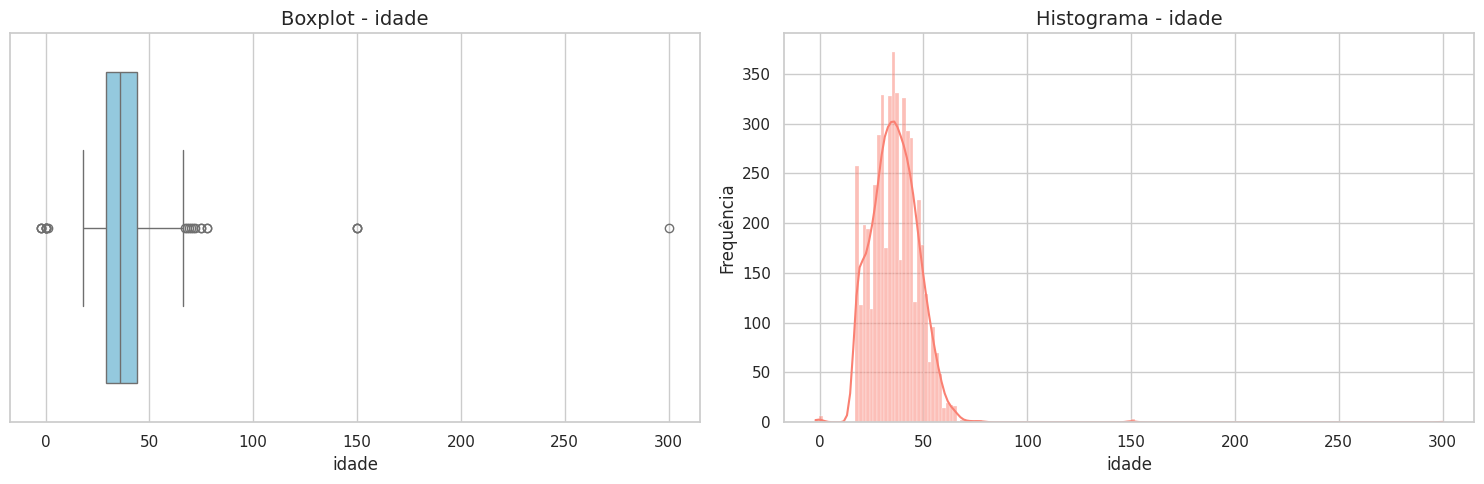

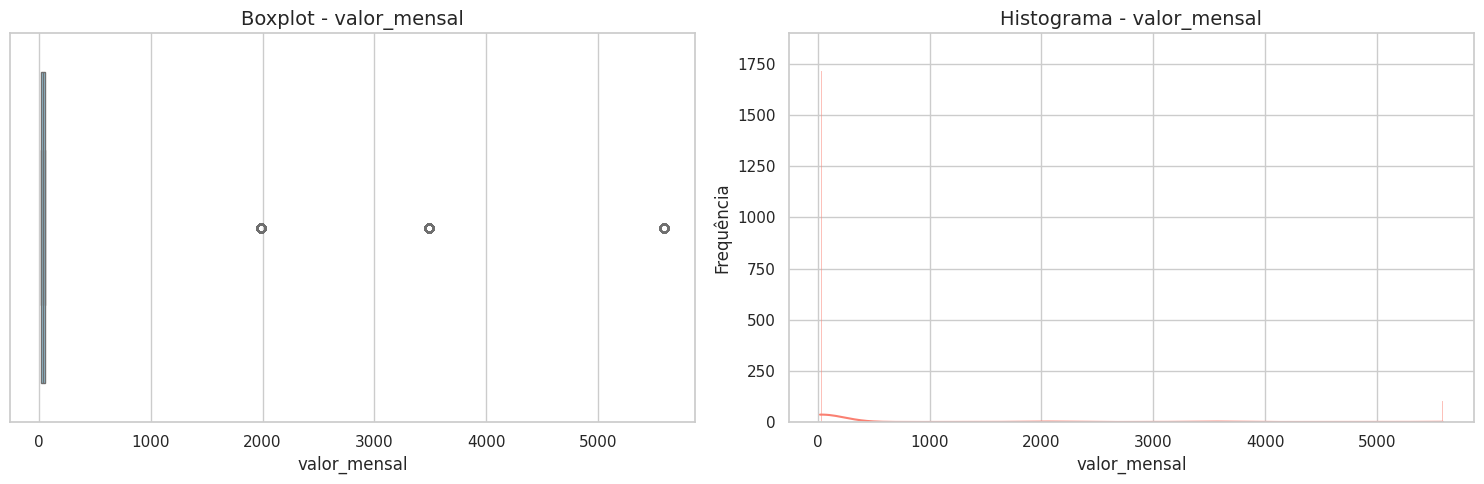

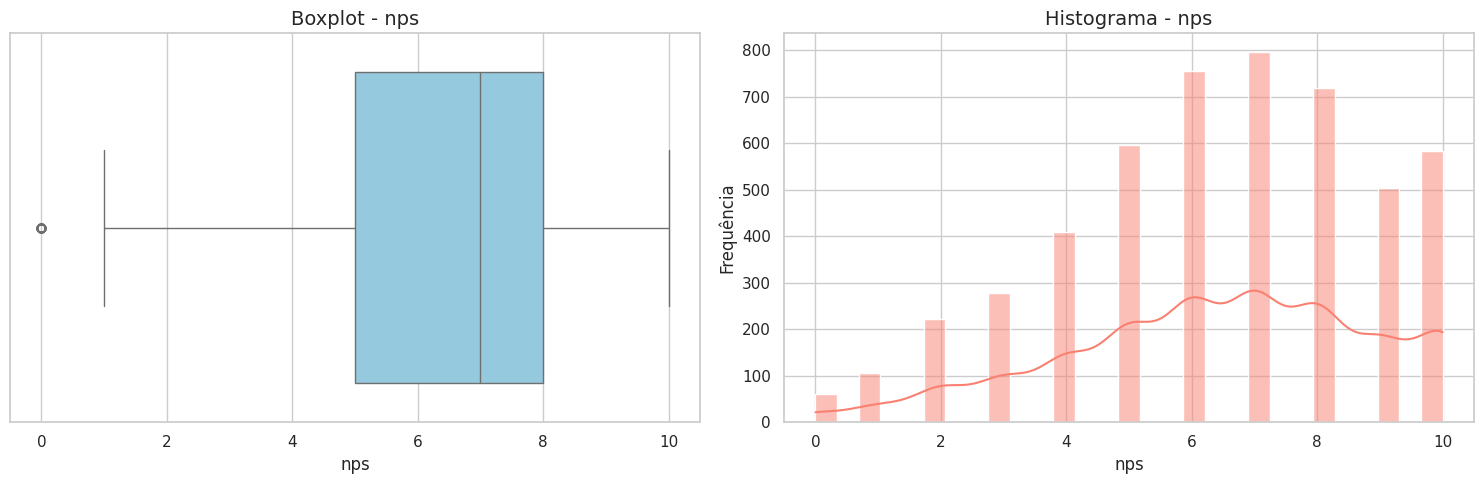

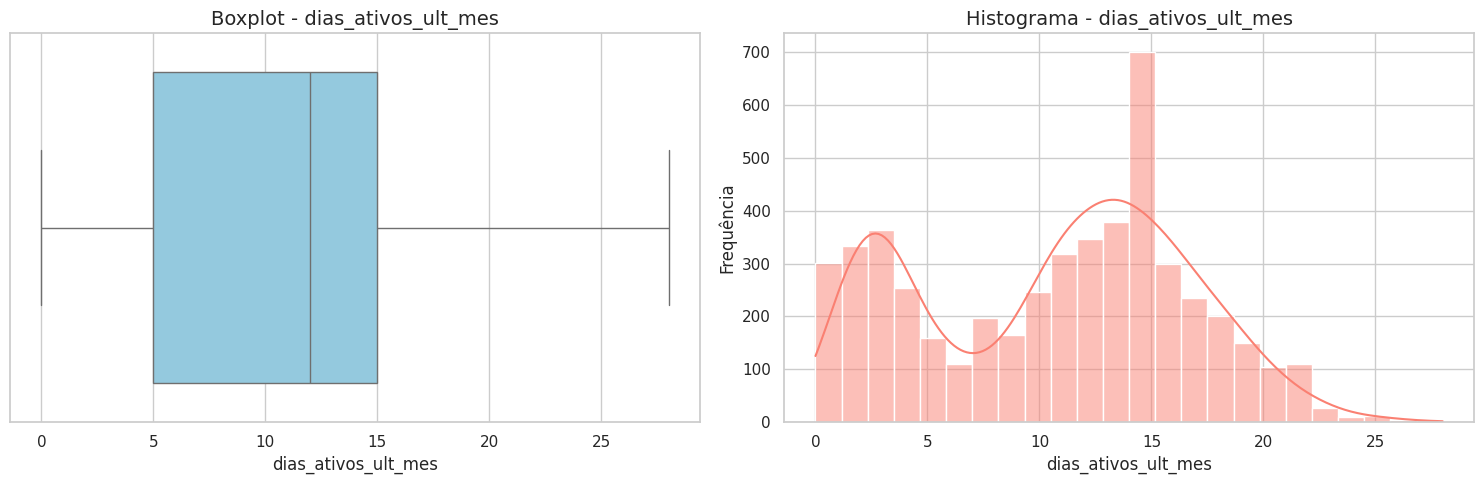

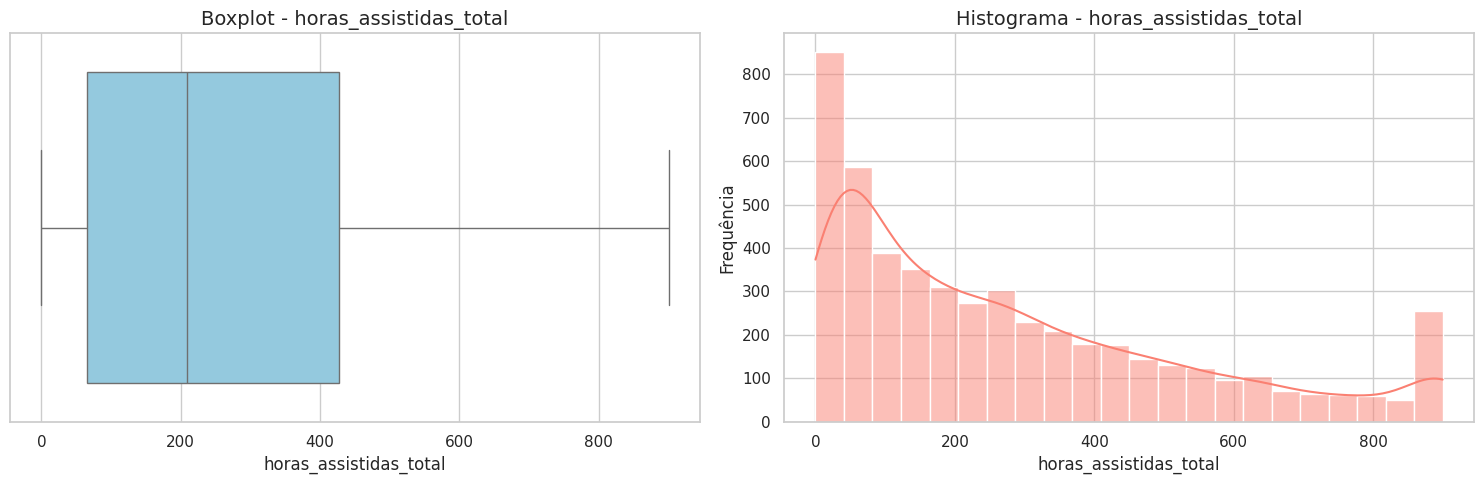

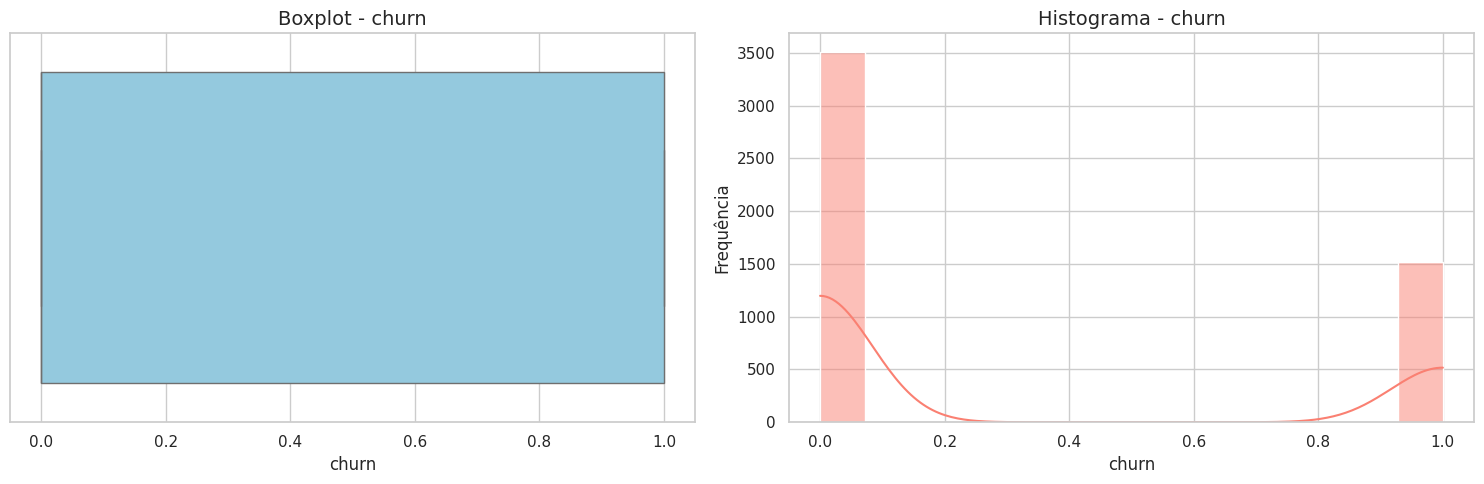

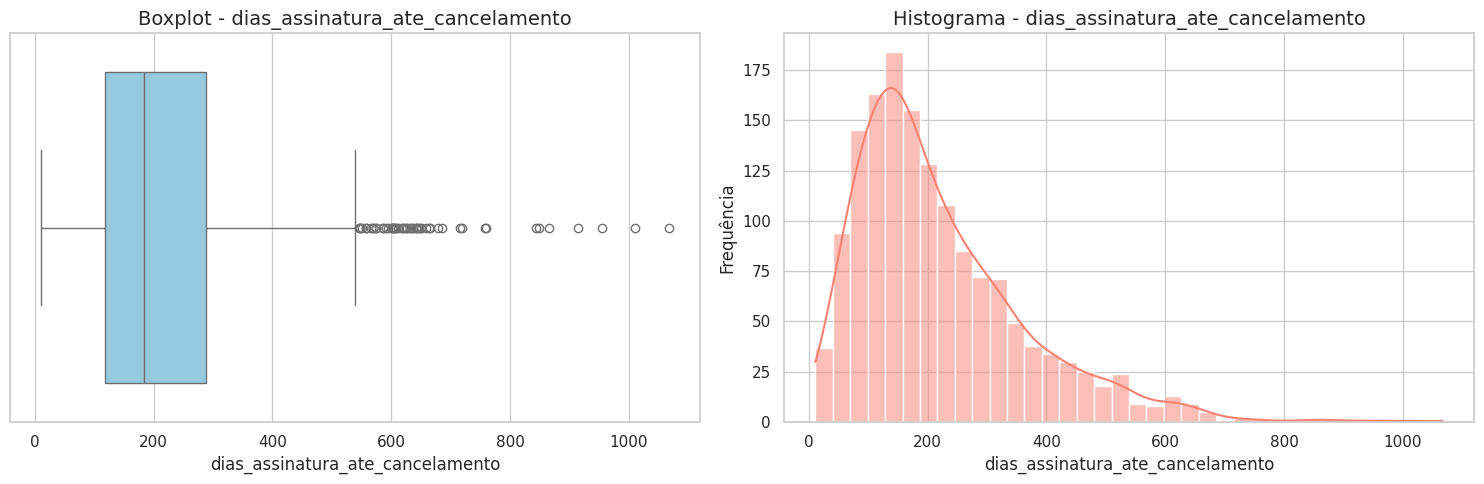

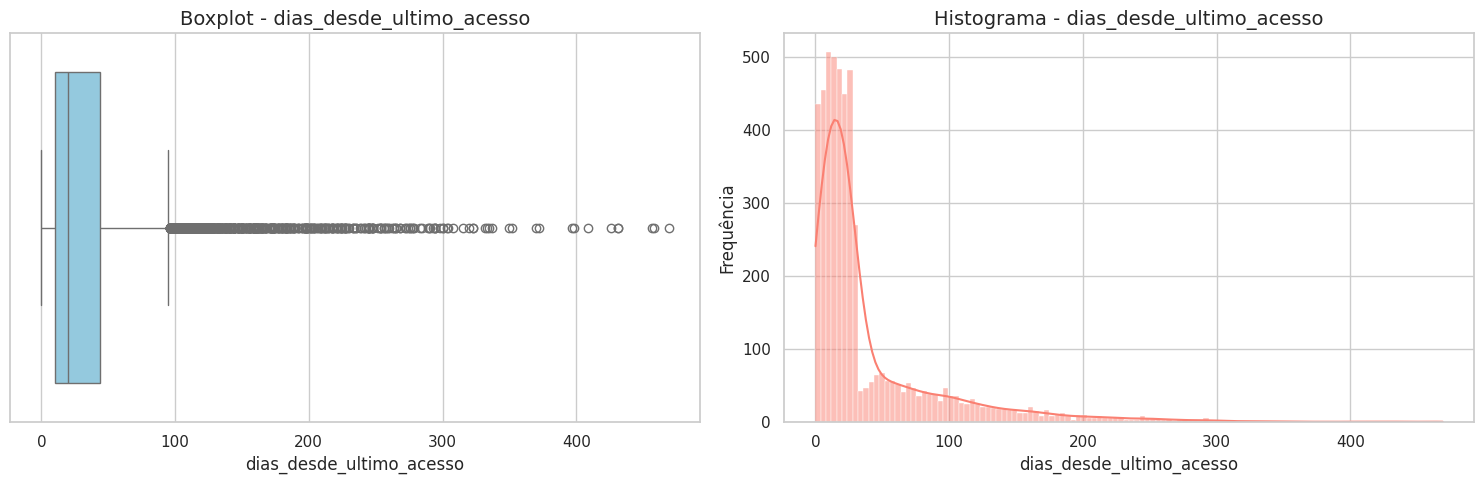

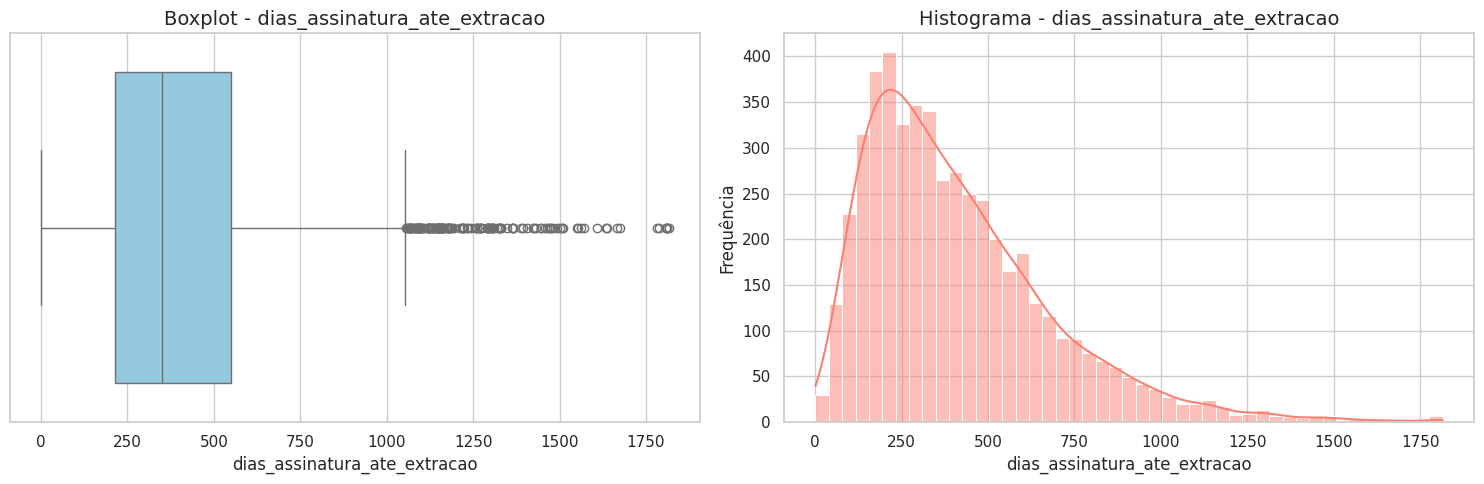

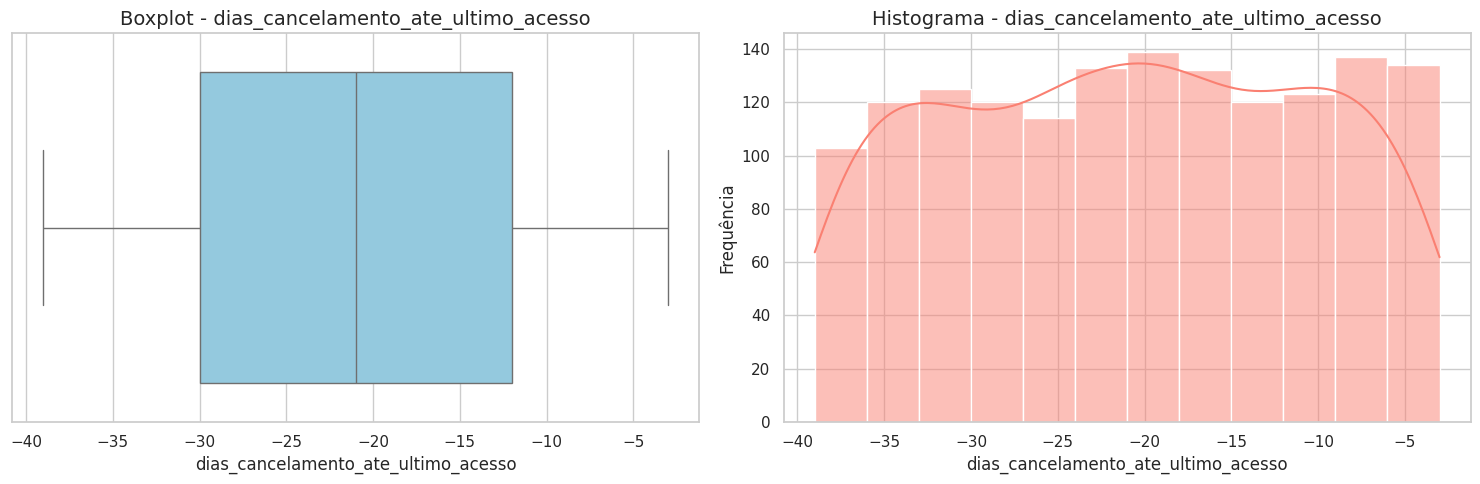

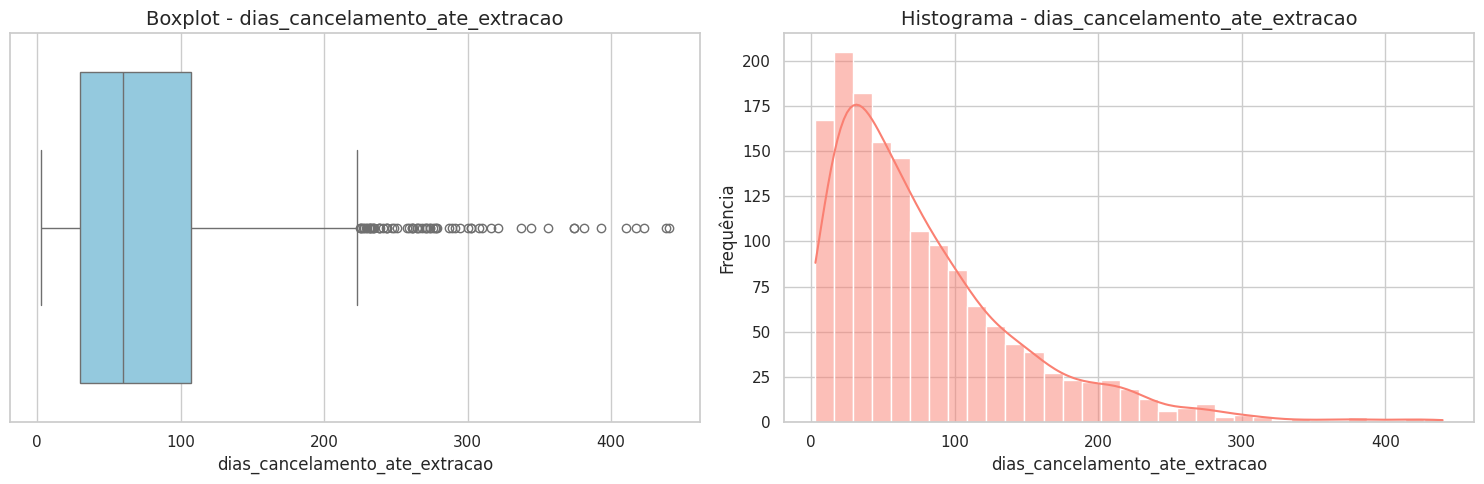

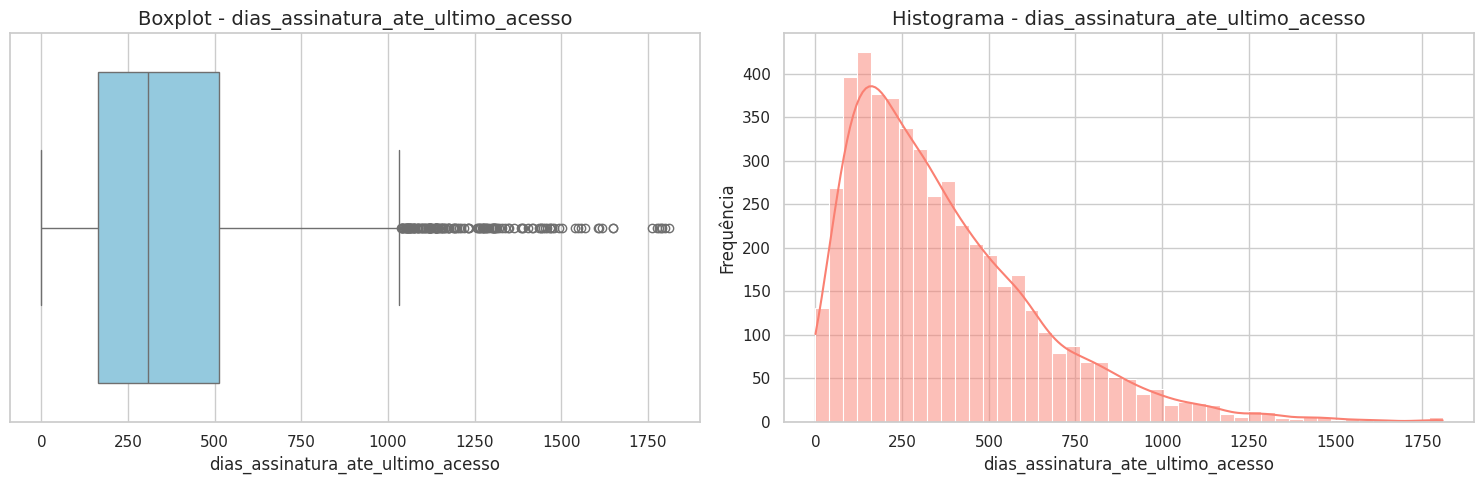

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Selecionar colunas numéricas excluindo 'cliente_id'
colunas_numericas = df_filtrado.select_dtypes(include=['int64', 'float64']).columns.tolist()
if 'cliente_id' in colunas_numericas:
    colunas_numericas.remove('cliente_id')

# Configurar o estilo visual dos gráficos
sns.set_theme(style="whitegrid")

# Gerar os gráficos para cada coluna numérica
for col in colunas_numericas:
    # Criar uma figura com 1 linha e 2 colunas para colocar o Boxplot e o Histograma lado a lado
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    # 1. Boxplot
    sns.boxplot(data=df_filtrado, x=col, ax=axes[0], color='skyblue')
    axes[0].set_title(f'Boxplot - {col}', fontsize=14)
    axes[0].set_xlabel(col, fontsize=12)

    # 2. Histograma
    sns.histplot(data=df_filtrado, x=col, kde=True, ax=axes[1], color='salmon')
    axes[1].set_title(f'Histograma - {col}', fontsize=14)
    axes[1].set_xlabel(col, fontsize=12)
    axes[1].set_ylabel('Frequência', fontsize=12)

    plt.tight_layout()
    plt.show()

In [ ]:
# Armazenar o tamanho original antes do filtro de idade
tamanho_anterior = len(df_filtrado)

# Filtrar idade mantendo apenas valores entre 18 e 90 anos (ou nulos se houver)
df_filtrado = df_filtrado[
    ((df_filtrado['idade'] >= 18) & (df_filtrado['idade'] <= 90)) |
    (df_filtrado['idade'].isnull())
]

# Exibir a quantidade de registros removidos
removidos = tamanho_anterior - len(df_filtrado)
print(f"Tamanho anterior: {tamanho_anterior} linhas")
print(f"Tamanho atual após filtro de idade: {len(df_filtrado)} linhas")
print(f"Foram removidas {removidos} linhas com idades fora do limite aceitável [18, 90].")

# Exibir estatísticas da idade atualizada para validação
display(df_filtrado['idade'].describe())

Tamanho anterior: 5024 linhas
Tamanho atual após filtro de idade: 5011 linhas
Foram removidas 13 linhas com idades fora do limite aceitável [18, 90].


,idade
count,5011.000000
mean,36.272401
std,10.615144
min,18.000000
25%,29.000000
50%,36.000000
75%,44.000000
max,78.000000


In [ ]:
# Filtrar e exibir linhas onde o valor mensal é superior a 1000
clientes_valor_alto = df_filtrado[df_filtrado['valor_mensal'] > 1000]

print(f"Quantidade de registros encontrados: {len(clientes_valor_alto)}")
display(clientes_valor_alto)

Quantidade de registros encontrados: 602


,cliente_id,idade,plano,ciclo,valor_mensal,regiao,canal_aquisicao,nps,data_assinatura,data_cancelamento,...,dias_ativos_ult_mes,horas_assistidas_total,motivo_cancelamento,churn,dias_assinatura_ate_cancelamento,dias_desde_ultimo_acesso,dias_assinatura_ate_extracao,dias_cancelamento_ate_ultimo_acesso,dias_cancelamento_ate_extracao,dias_assinatura_ate_ultimo_acesso
3,3454,46,BASICO,Anual,1990.0,Sul,Google,10,2023-04-02,NaT,...,19,385.0,NaN,0,NaN,18.0,304,NaN,NaN,286.0
14,5581,18,Padrao,Mensal,3490.0,Sudeste,orgânico,7,2023-07-22,NaT,...,15,160.7,NaN,0,NaN,4.0,193,NaN,NaN,189.0
29,5979,31,Padrão,Mensal,3490.0,Sudeste,Instagram,10,2023-08-22,NaT,...,14,117.2,NaN,0,NaN,28.0,162,NaN,NaN,134.0
34,1433,56,Padrão,Anual,3490.0,?,orgânico,9,2023-04-14,NaT,...,11,180.4,NaN,0,NaN,9.0,292,NaN,NaN,283.0
42,4776,61,básico,Anual,1990.0,Sudeste,orgânico,4,2023-10-01,2023-12-15,...,6,47.8,problema tecnico,1,75.0,67.0,122,-20.0,47.0,55.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4979,4984,30,Padrao,Anual,3490.0,Sudeste,indicação,7,2020-12-01,NaT,...,20,900.0,NaN,0,NaN,18.0,1156,NaN,NaN,1138.0
4991,2396,23,padrão,Anual,3490.0,Nordeste,Organico,8,2021-04-14,NaT,...,18,900.0,NaN,0,NaN,5.0,1022,NaN,NaN,1017.0
5000,5926,37,Padrão,Anual,3490.0,Centro-Oeste,orgânico,10,2022-12-01,NaT,...,9,243.6,NaN,0,NaN,24.0,426,NaN,NaN,402.0
5006,4388,18,básico,Anual,1990.0,Nordeste,IG,9,2023-05-03,NaT,...,11,160.6,NaN,0,NaN,22.0,273,NaN,NaN,251.0


In [ ]:
# Contar os valores distintos da coluna valor_mensal, incluindo nulos se houver
print("Contagem de valores distintos na coluna 'valor_mensal':")
display(df_filtrado['valor_mensal'].value_counts(dropna=False))

Contagem de valores distintos na coluna 'valor_mensal':


,count
valor_mensal,
19.9,1806
34.9,1712
55.9,891
1990.0,252
3490.0,246
5590.0,104


In [ ]:
# Corrigir os valores da coluna valor_mensal dividindo por 100 onde o valor é maior que 1900
df_filtrado.loc[df_filtrado['valor_mensal'] > 1900, 'valor_mensal'] = df_filtrado.loc[df_filtrado['valor_mensal'] > 1900, 'valor_mensal'] / 100

# Exibir a nova contagem de valores distintos para validação
print("Nova distribuição de 'valor_mensal' após correção:")
display(df_filtrado['valor_mensal'].value_counts(dropna=False))

Nova distribuição de 'valor_mensal' após correção:


,count
valor_mensal,
19.9,2058
34.9,1958
55.9,995


In [ ]:
##Conclusões da univariada - variáveis categóricas
#1. Base suja
  #plano: foi padronizado o nome do plano para um mesmo padrão para todas as linhas.
  #canal_aquisicao: padronizado também onde se tinh Organico/orgânico, indicacao/indicação, IG/instagram/Instagram e google/Google
#2. O ? na região é ausente disfarçado (eram 170 registros com ? que o 'isnull()' não pega porque é texto.
#3. Insight do negocio real - a base é fortemente concentrada no Sudeste.
#4. Insight do negocio - o produto é predominantemente mensal
#5. A Distribuição dos canais é equilibrada - nenhum domina.

In [ ]:
import pandas as pd
import numpy as np
import os
from google.colab import drive

# Forçar montagem limpa do Google Drive
try:
    drive.mount('/content/drive', force_remount=True)
    print("Google Drive montado com sucesso!")
except Exception as e:
    print(f"Erro ao montar o Google Drive: {e}")

# Verificar caminhos válidos
caminho_pasta = '/content/drive/MyDrive/UNIPDS/Modulo_3'
if not os.path.exists(caminho_pasta):
    caminho_pasta = '/content/drive/My Drive/UNIPDS/Modulo_3'
caminho_arquivo = os.path.join(caminho_pasta, 'clientes_base.csv')

# 1. Carregamento dos dados
df = pd.read_csv(caminho_arquivo)

# 2. Conversão de datas
colunas_data = ['data_assinatura', 'data_cancelamento', 'data_ultimo_acesso', 'data_extracao']
for col in colunas_data:
    df[col] = pd.to_datetime(df[col], errors='coerce')

# 3. Limpeza de nulos ocultos e padronização
df = df.replace('?', np.nan)

mapeamento_plano = {
    'BASICO': 'básico', 'Basico': 'básico', 'básico': 'básico',
    'Padrao': 'padrão', 'Padrão': 'padrão', 'padrão': 'padrão',
    'Premium': 'premium', 'premium': 'premium'
}
df['plano'] = df['plano'].map(mapeamento_plano).fillna(df['plano'])

mapeamento_canal = {
    'Organico': 'orgânico', 'Indicacao': 'indicação',
    'IG': 'instagram', 'Instagram': 'instagram', 'Google': 'google'
}
df['canal_aquisicao'] = df['canal_aquisicao'].replace(mapeamento_canal)

# 4. Criação das variáveis de intervalo de tempo
df['dias_assinatura_ate_cancelamento'] = (df['data_cancelamento'] - df['data_assinatura']).dt.days
df['dias_desde_ultimo_acesso'] = (df['data_extracao'] - df['data_ultimo_acesso']).dt.days
df['dias_assinatura_ate_extracao'] = (df['data_extracao'] - df['data_assinatura']).dt.days
df['dias_cancelamento_ate_extracao'] = (df['data_extracao'] - df['data_cancelamento']).dt.days
df['dias_cancelamento_ate_ultimo_acesso'] = (df['data_ultimo_acesso'] - df['data_cancelamento']).dt.days
df['dias_assinatura_ate_ultimo_acesso'] = (df['data_ultimo_acesso'] - df['data_assinatura']).dt.days

# 5. Criação do df_filtrado aplicando os filtros de sanidade (idade e inconsistência temporal)
df_filtrado = df[
    ((df['dias_assinatura_ate_ultimo_acesso'] >= 0) | (df['dias_assinatura_ate_ultimo_acesso'].isnull())) &
    (((df['idade'] >= 18) & (df['idade'] <= 90)) | (df['idade'].isnull()))
].copy()

# 6. Correção de escala da coluna valor_mensal
df_filtrado.loc[df_filtrado['valor_mensal'] > 1900, 'valor_mensal'] = df_filtrado.loc[df_filtrado['valor_mensal'] > 1900, 'valor_mensal'] / 100

# 7. Adição das colunas calculadas de recência, meses e receita
df_filtrado['recencia'] = (df_filtrado['data_extracao'] - df_filtrado['data_ultimo_acesso']).dt.days
df_filtrado['meses_assinatura'] = np.where(
    df_filtrado['data_cancelamento'].isnull(),
    (df_filtrado['data_extracao'] - df_filtrado['data_assinatura']).dt.days / 30,
    (df_filtrado['data_cancelamento'] - df_filtrado['data_assinatura']).dt.days / 30
)
df_filtrado['receita_acumulada'] = df_filtrado['valor_mensal'] * df_filtrado['meses_assinatura']

# 8. Criar o DataFrame df_analise conforme solicitado pelo usuário
df_analise = df_filtrado[df_filtrado['dias_assinatura_ate_extracao'] >= 220].copy()

# Exibir a validação do filtro
print(f"\nTamanho do df_filtrado original recomposto: {len(df_filtrado)} linhas")
print(f"Tamanho do novo df_analise: {len(df_analise)} linhas")
print(f"Registros filtrados (removidos): {len(df_filtrado) - len(df_analise)}\n")

print("--- Estatísticas de 'dias_assinatura_ate_extracao' no df_analise ---")
display(df_analise['dias_assinatura_ate_extracao'].describe())

# Exibir amostra rápida do df_analise criado
display(df_analise[['cliente_id', 'dias_assinatura_ate_extracao', 'valor_mensal', 'receita_acumulada']].head())

Mounted at /content/drive
Google Drive montado com sucesso!

Tamanho do df_filtrado original recomposto: 5011 linhas
Tamanho do novo df_analise: 3668 linhas
Registros filtrados (removidos): 1343

--- Estatísticas de 'dias_assinatura_ate_extracao' no df_analise ---


,dias_assinatura_ate_extracao
count,3668.000000
mean,510.439204
std,251.757349
min,220.000000
25%,321.000000
50%,445.000000
75%,626.000000
max,1815.000000


,cliente_id,dias_assinatura_ate_extracao,valor_mensal,receita_acumulada
0,5746,295,19.9,195.683333
1,4100,608,34.9,707.306667
2,4690,1047,55.9,1131.043333
3,3454,304,19.9,201.653333
4,1437,285,19.9,189.050000


Taxa Geral de Churn no df_analise: 24.21%

--- Médias das Variáveis Numéricas por Status de Churn ---


,Não Churn (0),Churn (1),Diferença (%)
idade,36.125540,36.632883,1.404390
recencia,14.603993,130.011390,790.245509
meses_assinatura,18.088873,10.006156,-44.683363
receita_acumulada,605.311556,315.519917,-47.874790
nps,7.376978,4.090090,-44.556025
dias_ativos_ult_mes,13.995324,2.967342,-78.797616
horas_assistidas_total,448.891475,73.143131,-83.705832


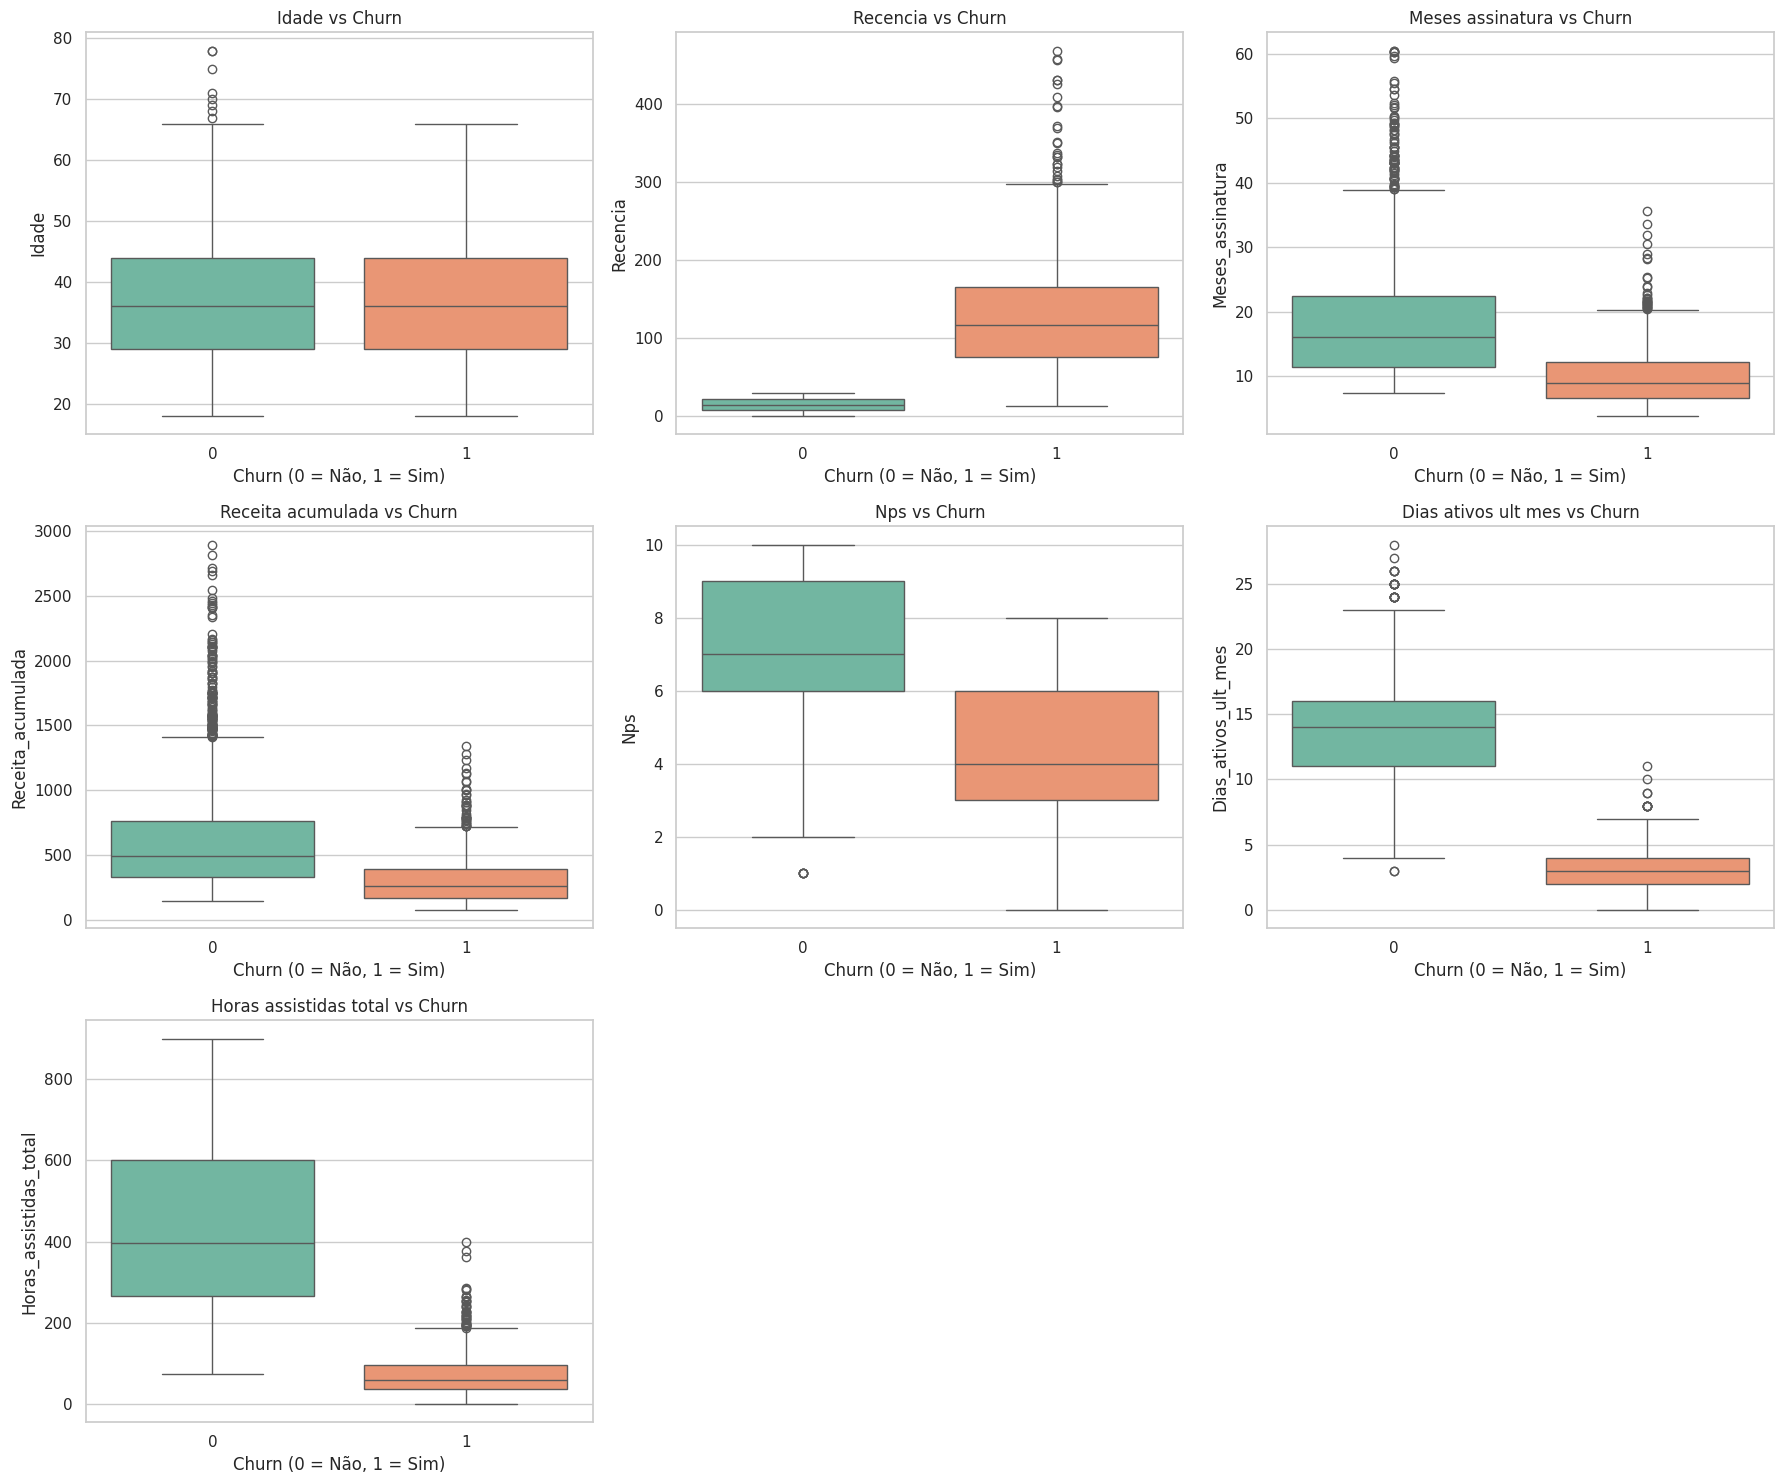


--- Taxa de Churn por Categoria ---

Análise para a coluna: plano


,plano,Total,Churns,Taxa_Churn_Pct
0,básico,1486,404,27.187079
1,padrão,1436,325,22.632312
2,premium,746,159,21.313673



Análise para a coluna: ciclo


,ciclo,Total,Churns,Taxa_Churn_Pct
1,Mensal,2752,668,24.273256
0,Anual,916,220,24.017467



Análise para a coluna: regiao


,regiao,Total,Churns,Taxa_Churn_Pct
0,Centro-Oeste,353,93,26.345609
2,Norte,297,76,25.589226
4,Sul,707,174,24.611033
1,Nordeste,719,172,23.922114
3,Sudeste,1464,338,23.087432



Análise para a coluna: canal_aquisicao


,canal_aquisicao,Total,Churns,Taxa_Churn_Pct
0,google,635,172,27.086614
2,instagram,1125,280,24.888889
3,orgânico,1111,255,22.952295
1,indicação,797,181,22.710163


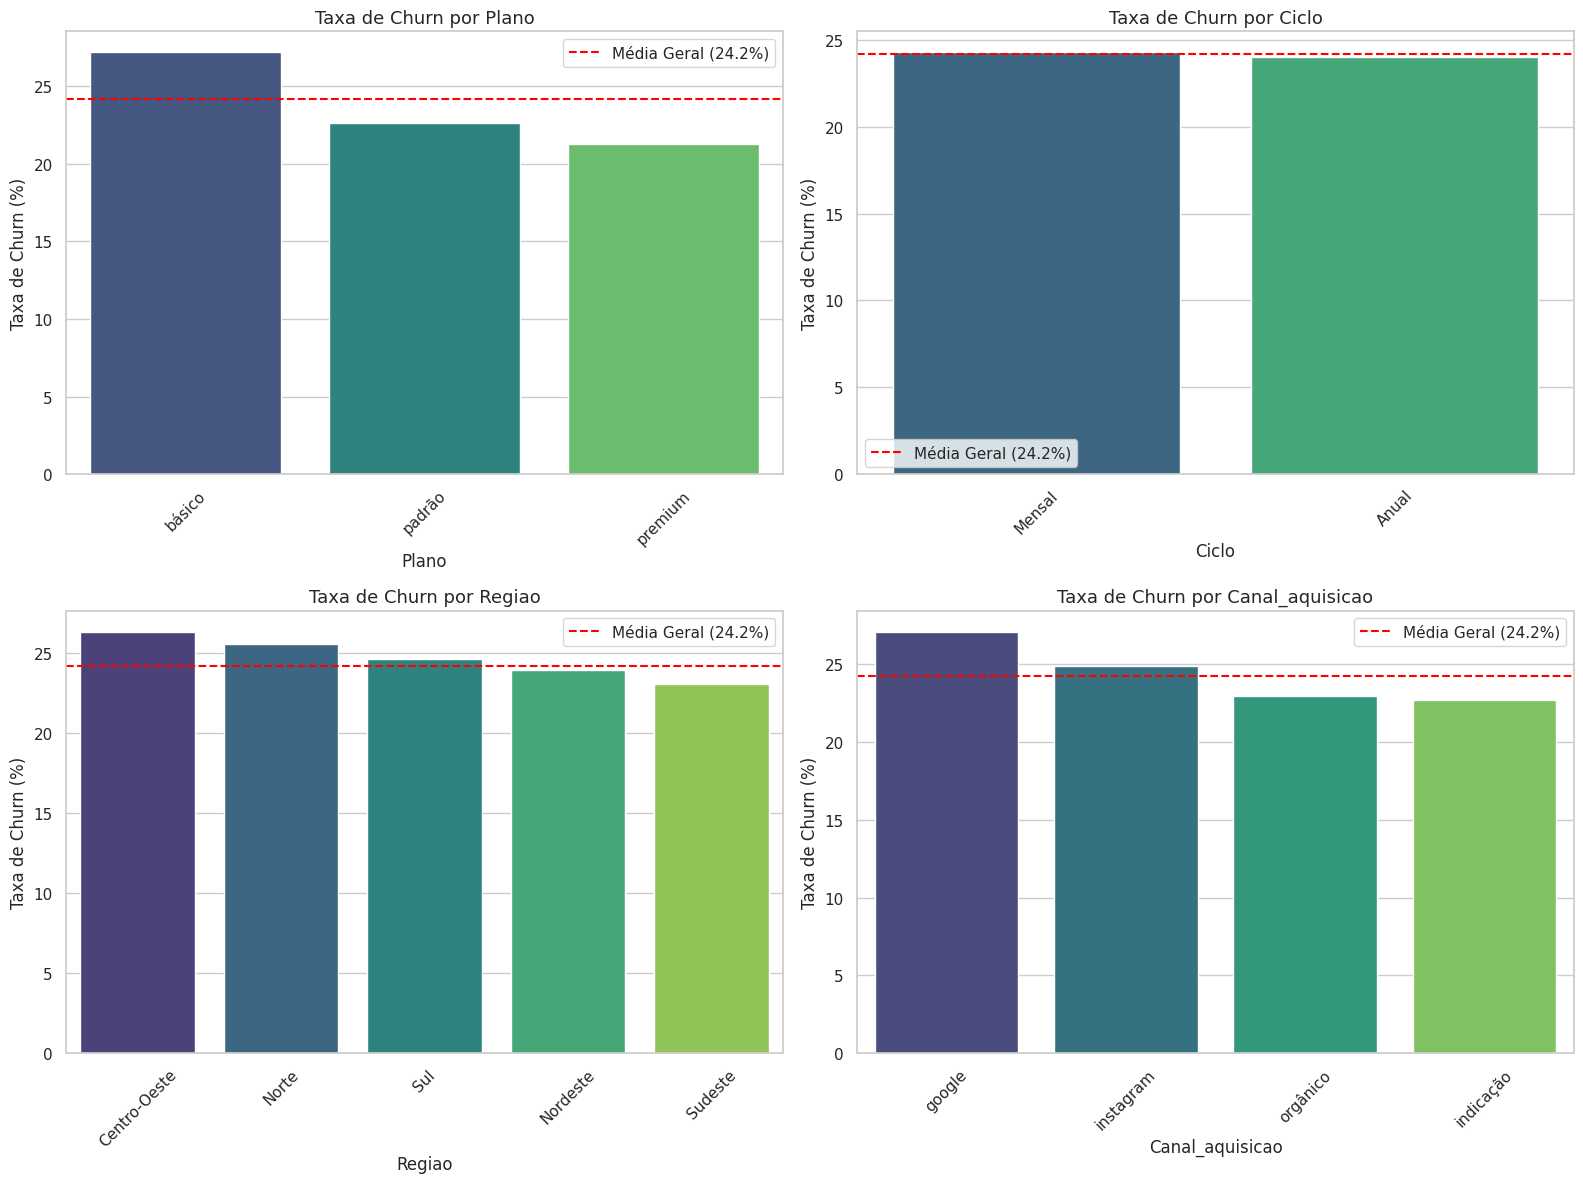

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Definir o estilo visual dos gráficos
sns.set_theme(style="whitegrid")

# Identificar taxa geral de Churn no df_analise
taxa_churn_geral = df_analise['churn'].mean() * 100
print(f"Taxa Geral de Churn no df_analise: {taxa_churn_geral:.2f}%\n")

# ==========================================
# 1. ANÁLISE DE VARIÁVEIS NUMÉRICAS VS CHURN
# ==========================================

colunas_numericas_analise = [
    'idade', 'recencia', 'meses_assinatura',
    'receita_acumulada', 'nps', 'dias_ativos_ult_mes',
    'horas_assistidas_total'
]

print("--- Médias das Variáveis Numéricas por Status de Churn ---")
medias_churn = df_analise.groupby('churn')[colunas_numericas_analise].mean().T
medias_churn.columns = ['Não Churn (0)', 'Churn (1)']
medias_churn['Diferença (%)'] = ((medias_churn['Churn (1)'] - medias_churn['Não Churn (0)']) / medias_churn['Não Churn (0)']) * 100
display(medias_churn)

# Plot de Boxplots comparativos para numéricas
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

for i, col in enumerate(colunas_numericas_analise):
    sns.boxplot(x='churn', y=col, data=df_analise, ax=axes[i], palette='Set2', hue='churn', legend=False)
    axes[i].set_title(f'{col.replace("_", " ").capitalize()} vs Churn', fontsize=12)
    axes[i].set_xlabel('Churn (0 = Não, 1 = Sim)')
    axes[i].set_ylabel(col.capitalize())

# Ocultar subplots vazios
for j in range(len(colunas_numericas_analise), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# ==========================================
# 2. ANÁLISE DE VARIÁVEIS CATEGÓRICAS VS CHURN
# ==========================================

colunas_categoricas_analise = ['plano', 'ciclo', 'regiao', 'canal_aquisicao']

print("\n--- Taxa de Churn por Categoria ---")
for col in colunas_categoricas_analise:
    if col in df_analise.columns:
        # Calcular frequência e taxa de churn por categoria
        analise_cat = df_analise.groupby(col).agg(
            Total=('churn', 'count'),
            Churns=('churn', 'sum'),
            Taxa_Churn_Pct=('churn', lambda x: x.mean() * 100)
        ).reset_index()

        print(f"\nAnálise para a coluna: {col}")
        display(analise_cat.sort_values(by='Taxa_Churn_Pct', ascending=False))

# Plot de Taxa de Churn para as Categóricas
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(colunas_categoricas_analise):
    if col in df_analise.columns:
        # Calcular a taxa de churn de cada categoria
        taxa_cat = df_analise.groupby(col)['churn'].mean().reset_index()
        taxa_cat['churn'] = taxa_cat['churn'] * 100
        taxa_cat = taxa_cat.sort_values(by='churn', ascending=False)

        sns.barplot(x=col, y='churn', data=taxa_cat, ax=axes[i], palette='viridis', hue=col, legend=False)
        axes[i].axhline(taxa_churn_geral, color='red', linestyle='--', label=f'Média Geral ({taxa_churn_geral:.1f}%)')
        axes[i].set_title(f'Taxa de Churn por {col.capitalize()}', fontsize=13)
        axes[i].set_ylabel('Taxa de Churn (%)')
        axes[i].set_xlabel(col.capitalize())
        axes[i].tick_params(axis='x', rotation=45)
        axes[i].legend()

plt.tight_layout()
plt.show()

=== ANÁLISE DAS VARIÁVEIS NUMÉRICAS VS CHURN ===


 ANÁLISE DA VARIÁVEL: IDADE

Tabela Estatística de 'idade' por status de Churn:


,Não Churn (0),Churn (1)
count,2780.000000,888.000000
mean,36.125540,36.632883
std,10.633567,10.600266
min,18.000000,18.000000
25%,29.000000,29.000000
50%,36.000000,36.000000
75%,44.000000,44.000000
max,78.000000,66.000000


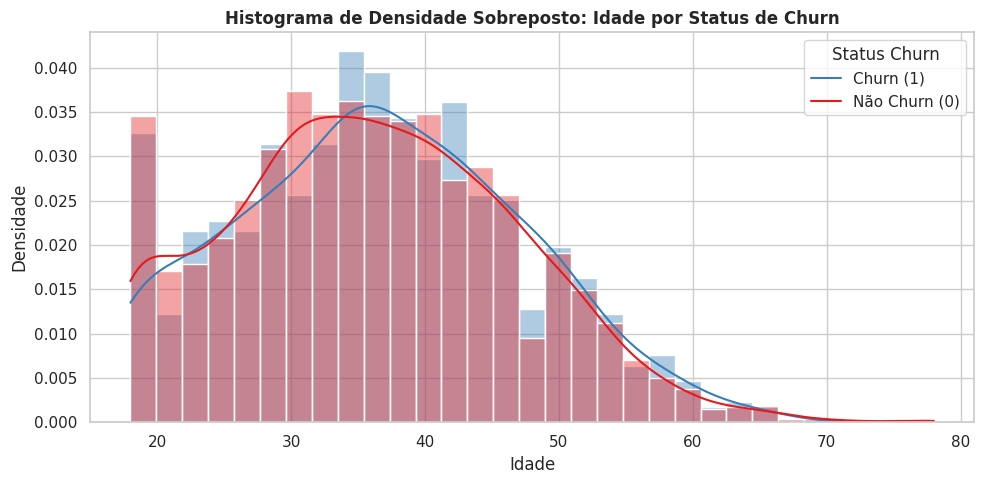


 ANÁLISE DA VARIÁVEL: VALOR_MENSAL

Tabela Estatística de 'valor_mensal' por status de Churn:


,Não Churn (0),Churn (1)
count,2780.000000,888.000000
mean,33.496043,31.835811
std,13.370968,13.119920
min,19.900000,19.900000
25%,19.900000,19.900000
50%,34.900000,34.900000
75%,34.900000,34.900000
max,55.900000,55.900000


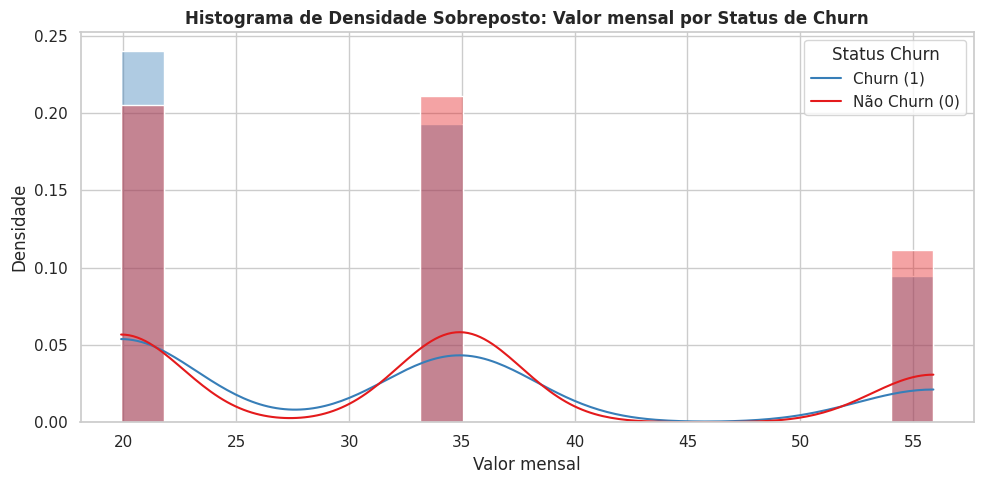


 ANÁLISE DA VARIÁVEL: NPS

Tabela Estatística de 'nps' por status de Churn:


,Não Churn (0),Churn (1)
count,2780.000000,888.000000
mean,7.376978,4.090090
std,1.877014,2.004165
min,1.000000,0.000000
25%,6.000000,3.000000
50%,7.000000,4.000000
75%,9.000000,6.000000
max,10.000000,8.000000


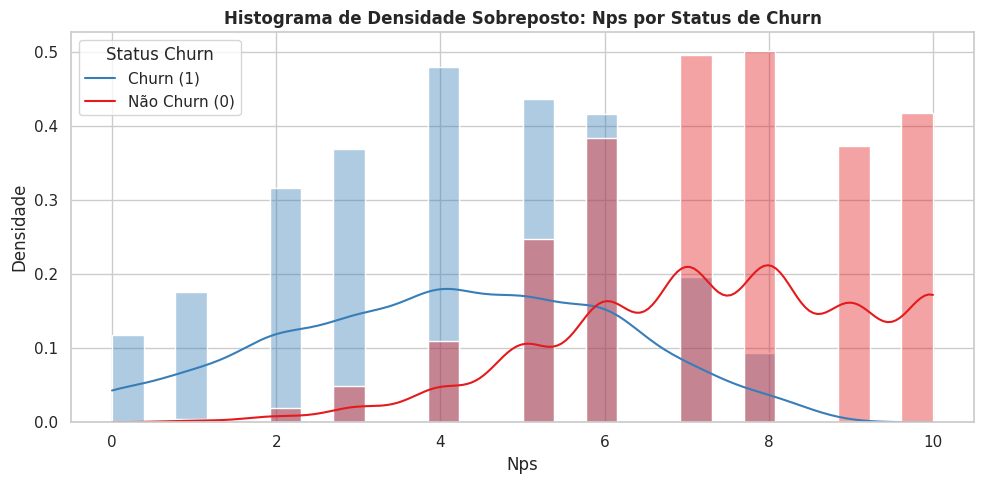


 ANÁLISE DA VARIÁVEL: DIAS_ATIVOS_ULT_MES

Tabela Estatística de 'dias_ativos_ult_mes' por status de Churn:


,Não Churn (0),Churn (1)
count,2780.000000,888.000000
mean,13.995324,2.967342
std,3.755046,1.721950
min,3.000000,0.000000
25%,11.000000,2.000000
50%,14.000000,3.000000
75%,16.000000,4.000000
max,28.000000,11.000000


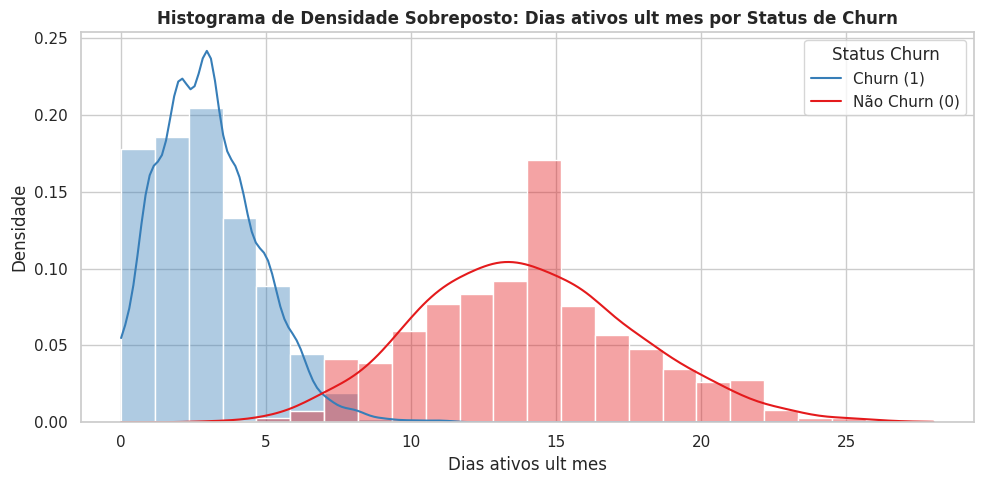


 ANÁLISE DA VARIÁVEL: HORAS_ASSISTIDAS_TOTAL

Tabela Estatística de 'horas_assistidas_total' por status de Churn:


,Não Churn (0),Churn (1)
count,2780.000000,888.000000
mean,448.891475,73.143131
std,226.739374,55.191559
min,73.900000,0.000000
25%,265.450000,35.925000
50%,395.600000,58.950000
75%,600.900000,96.600000
max,900.000000,400.000000


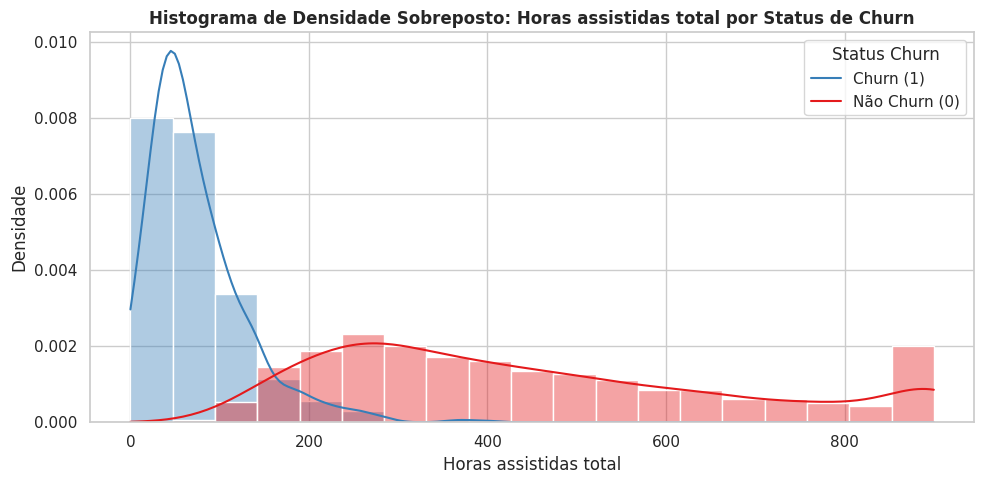


 ANÁLISE DA VARIÁVEL: DIAS_ASSINATURA_ATE_ULTIMO_ACESSO

Tabela Estatística de 'dias_assinatura_ate_ultimo_acesso' por status de Churn:


,Não Churn (0),Churn (1)
count,2755.000000,878.000000
mean,528.301270,278.715262
std,266.179458,138.580418
min,192.000000,90.000000
25%,327.000000,176.000000
50%,465.000000,244.000000
75%,659.000000,342.500000
max,1809.000000,1040.000000


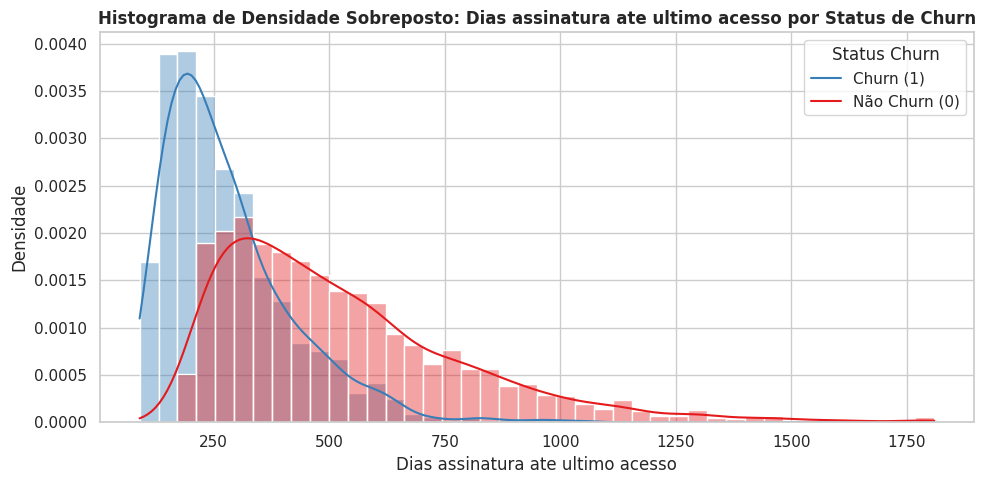


 ANÁLISE DA VARIÁVEL: DIAS_ASSINATURA_ATE_EXTRACAO

Tabela Estatística de 'dias_assinatura_ate_extracao' por status de Churn:


,Não Churn (0),Churn (1)
count,2780.000000,888.000000
mean,542.666187,409.548423
std,265.461831,166.733604
min,220.000000,220.000000
25%,341.000000,282.000000
50%,481.000000,364.500000
75%,673.250000,495.000000
max,1815.000000,1276.000000


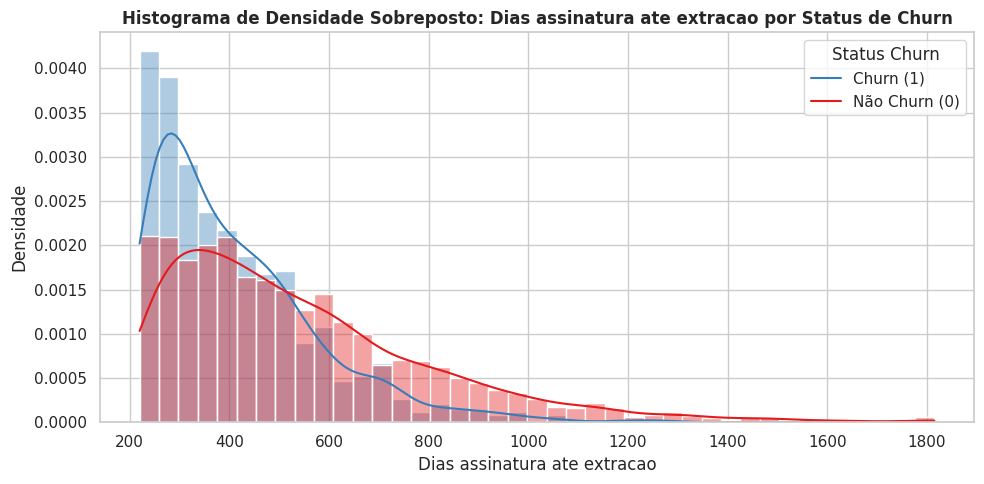


 ANÁLISE DA VARIÁVEL: RECENCIA

Tabela Estatística de 'recencia' por status de Churn:


,Não Churn (0),Churn (1)
count,2755.000000,878.000000
mean,14.603993,130.011390
std,8.493044,74.106997
min,0.000000,13.000000
25%,8.000000,75.250000
50%,14.000000,117.000000
75%,22.000000,165.000000
max,29.000000,469.000000


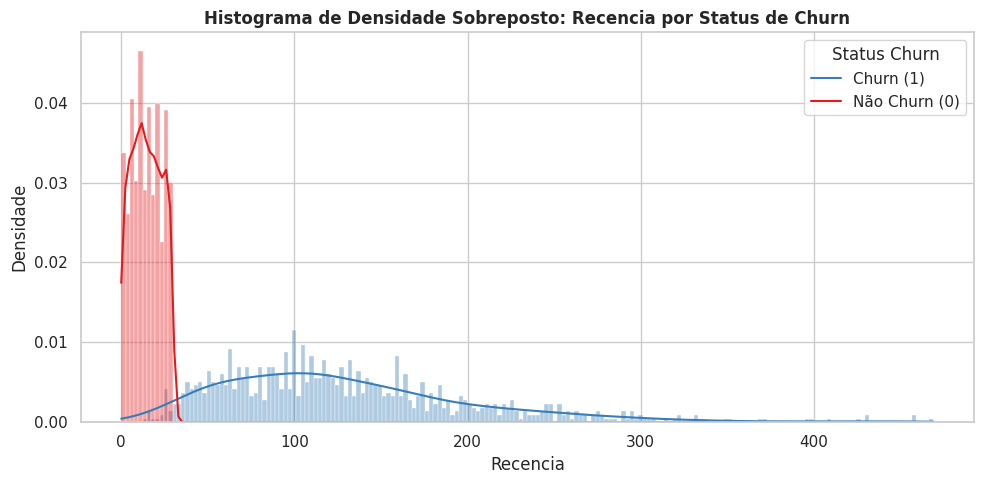


 ANÁLISE DA VARIÁVEL: MESES_ASSINATURA

Tabela Estatística de 'meses_assinatura' por status de Churn:


,Não Churn (0),Churn (1)
count,2780.000000,888.000000
mean,18.088873,10.006156
std,8.848728,4.615595
min,7.333333,3.800000
25%,11.366667,6.666667
50%,16.033333,8.900000
75%,22.441667,12.108333
max,60.500000,35.566667


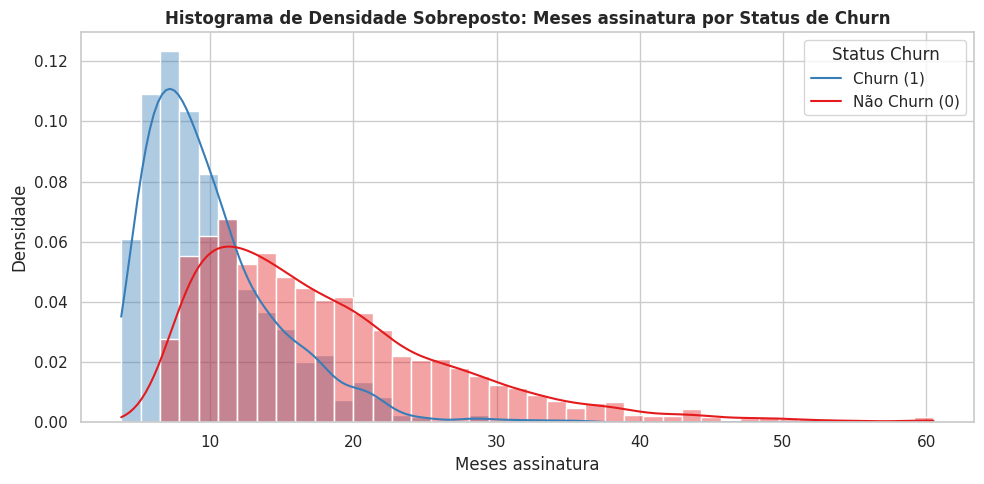


 ANÁLISE DA VARIÁVEL: RECEITA_ACUMULADA

Tabela Estatística de 'receita_acumulada' por status de Churn:


,Não Churn (0),Churn (1)
count,2780.000000,888.000000
mean,605.311556,315.519917
std,396.917467,195.137065
min,145.933333,77.610000
25%,329.013333,172.173333
50%,491.508333,262.680000
75%,762.103333,392.043333
max,2893.756667,1341.600000


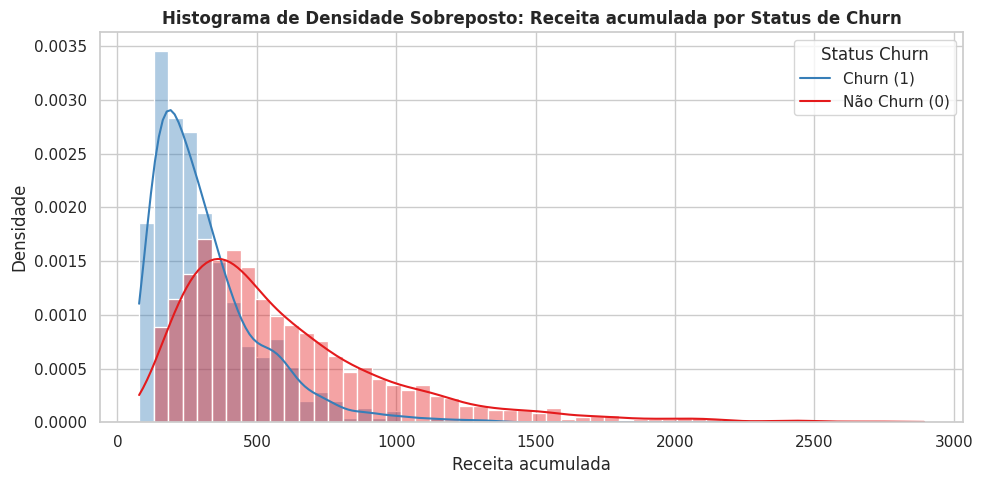


=== ANÁLISE DAS VARIÁVEIS CATEGÓRICAS VS CHURN ===


Taxa de Churn por categoria da variável: PLANO


,plano,Total_Clientes,Qtd_Churn,Taxa_Churn_Pct
0,básico,1486,404,27.187079
1,padrão,1436,325,22.632312
2,premium,746,159,21.313673



Taxa de Churn por categoria da variável: CICLO


,ciclo,Total_Clientes,Qtd_Churn,Taxa_Churn_Pct
1,Mensal,2752,668,24.273256
0,Anual,916,220,24.017467



Taxa de Churn por categoria da variável: REGIAO


,regiao,Total_Clientes,Qtd_Churn,Taxa_Churn_Pct
0,Centro-Oeste,353,93,26.345609
2,Norte,297,76,25.589226
4,Sul,707,174,24.611033
1,Nordeste,719,172,23.922114
3,Sudeste,1464,338,23.087432



Taxa de Churn por categoria da variável: CANAL_AQUISICAO


,canal_aquisicao,Total_Clientes,Qtd_Churn,Taxa_Churn_Pct
0,google,635,172,27.086614
2,instagram,1125,280,24.888889
3,orgânico,1111,255,22.952295
1,indicação,797,181,22.710163


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Definir o estilo visual dos gráficos
sns.set_theme(style="whitegrid")

# Listas de variáveis fornecidas pelo usuário
var_numericas = [
    'idade', 'valor_mensal', 'nps', 'dias_ativos_ult_mes',
    'horas_assistidas_total', 'dias_assinatura_ate_ultimo_acesso',
    'dias_assinatura_ate_extracao', 'recencia', 'meses_assinatura',
    'receita_acumulada'
]

var_categoricas = ['plano', 'ciclo', 'regiao', 'canal_aquisicao']

# =========================================================================
# 1. ANÁLISE DAS VARIÁVEIS NUMÉRICAS
# =========================================================================
print("=== ANÁLISE DAS VARIÁVEIS NUMÉRICAS VS CHURN ===\n")

for col in var_numericas:
    if col in df_analise.columns:
        print(f"\n" + "="*80)
        print(f" ANÁLISE DA VARIÁVEL: {col.upper()}")
        print("="*80 + "\n")

        # 1.1 Tabela de Estatísticas por Grupo de Churn
        print(f"Tabela Estatística de '{col}' por status de Churn:")
        estatisticas = df_analise.groupby('churn')[col].describe().T
        estatisticas.columns = ['Não Churn (0)', 'Churn (1)']
        display(estatisticas)

        # 1.2 Histograma de Densidade Sobreposto
        plt.figure(figsize=(10, 5))
        sns.histplot(
            data=df_analise,
            x=col,
            hue='churn',
            kde=True,
            stat='density',
            common_norm=False,
            palette='Set1',
            alpha=0.4
        )
        plt.title(f'Histograma de Densidade Sobreposto: {col.replace("_", " ").capitalize()} por Status de Churn', fontsize=12, fontweight='bold')
        plt.xlabel(col.replace("_", " ").capitalize())
        plt.ylabel('Densidade')
        plt.legend(title='Status Churn', labels=['Churn (1)', 'Não Churn (0)'])
        plt.tight_layout()
        plt.show()

# =========================================================================
# 2. ANÁLISE DAS VARIÁVEIS CATEGÓRICAS
# =========================================================================
print("\n=== ANÁLISE DAS VARIÁVEIS CATEGÓRICAS VS CHURN ===\n")

for col in var_categoricas:
    if col in df_analise.columns:
        print(f"\nTaxa de Churn por categoria da variável: {col.upper()}")

        # Calcular a taxa de churn por categoria
        tabela_cat = df_analise.groupby(col).agg(
            Total_Clientes=('churn', 'count'),
            Qtd_Churn=('churn', 'sum'),
            Taxa_Churn_Pct=('churn', lambda x: x.mean() * 100)
        ).reset_index()

        # Ordenar pela maior taxa de churn
        tabela_cat = tabela_cat.sort_values(by='Taxa_Churn_Pct', ascending=False)
        display(tabela_cat)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filtrar apenas os clientes cancelados e que possuem o motivo de cancelamento preenchido
df_cancelados = df_filtrado[df_filtrado['motivo_cancelamento'].notnull()].copy()

# Padronizar o texto dos motivos de cancelamento para evitar duplicidades por diferença de caixa alta/baixa
df_cancelados['motivo_cancelamento'] = df_cancelados['motivo_cancelamento'].str.strip().str.upper()

# 2. Calcular frequências absolutas e relativas para a Análise de Pareto
pareto_data = df_cancelados['motivo_cancelamento'].value_counts().reset_index()
pareto_data.columns = ['motivo_cancelamento', 'frequencia']

# Calcular percentuais e acumulados
pareto_data['percentual'] = (pareto_data['frequencia'] / pareto_data['frequencia'].sum()) * 100
pareto_data['frequencia_acumulada'] = pareto_data['frequencia'].cumsum()
pareto_data['percentual_acumulado'] = (pareto_data['frequencia_acumulada'] / pareto_data['frequencia'].sum()) * 100

print("=== TABELA DE PARETO: MOTIVOS DE CANCELAMENTO ===")
display(pareto_data)


=== TABELA DE PARETO: MOTIVOS DE CANCELAMENTO ===


,motivo_cancelamento,frequencia,percentual,frequencia_acumulada,percentual_acumulado
0,POUCO CONTEÚDO NOVO,384,25.413633,384,25.413633
1,PREÇO,331,21.906023,715,47.319656
2,PRECO,176,11.647915,891,58.967571
3,FALTA DE TEMPO,174,11.515553,1065,70.483124
4,PROBLEMA TECNICO,134,8.868299,1199,79.351423
5,CONCORRENTE,130,8.603574,1329,87.954997
6,PROBLEMA TÉCNICO,115,7.610854,1444,95.565850
7,OUTRO,67,4.434150,1511,100.000000


/tmp/ipykernel_1319/811483040.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(pareto_data['motivo_cancelamento'], rotation=45, ha='right')


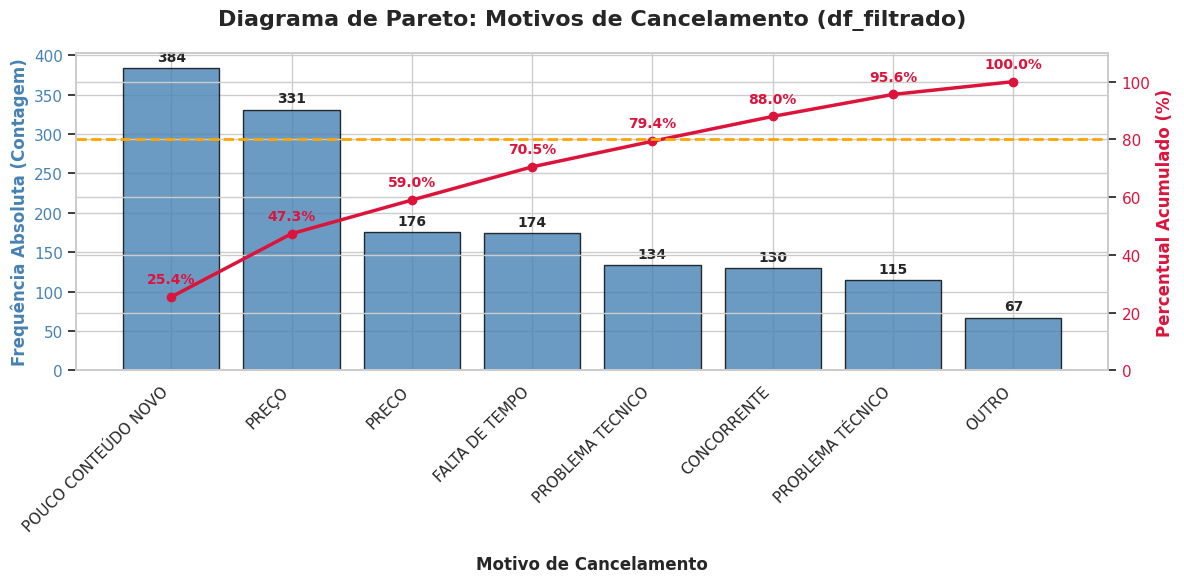

In [ ]:
# 3. Construir o gráfico de Pareto
fig, ax1 = plt.subplots(figsize=(12, 6))

# Configurar estilo visual
sns.set_theme(style="whitegrid")

# Gráfico de barras (eixo y esquerdo) para a frequência absoluta
color1 = 'steelblue'
ax1.set_xlabel('Motivo de Cancelamento', fontsize=12, fontweight='bold', labelpad=15)
ax1.set_ylabel('Frequência Absoluta (Contagem)', color=color1, fontsize=12, fontweight='bold')
bars = ax1.bar(pareto_data['motivo_cancelamento'], pareto_data['frequencia'], color=color1, alpha=0.8, edgecolor='black')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_xticklabels(pareto_data['motivo_cancelamento'], rotation=45, ha='right')

# Adicionar rótulos de dados nas barras
for bar in bars:
    height = bar.get_height()
    ax1.annotate(f'{int(height)}',
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3),  # 3 points vertical offset
                 textcoords="offset points",
                 ha='center', va='bottom', fontsize=10, fontweight='semibold')

# Criar um segundo eixo y compartilhado (eixo y direito) para a linha de percentual acumulado
ax2 = ax1.twinx()
color2 = 'crimson'
ax2.set_ylabel('Percentual Acumulado (%)', color=color2, fontsize=12, fontweight='bold')
ax2.plot(pareto_data['motivo_cancelamento'], pareto_data['percentual_acumulado'], color=color2, marker='o', linewidth=2.5, label='% Acumulado')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.set_ylim(0, 110) # Garantir espaço para a legenda e rótulos

# Adicionar rótulos de dados na linha de percentual acumulado
for i, txt in enumerate(pareto_data['percentual_acumulado']):
    ax2.annotate(f'{txt:.1f}%',
                 (pareto_data['motivo_cancelamento'][i], pareto_data['percentual_acumulado'][i]),
                 textcoords="offset points",
                 xytext=(0,10), # Posicionar ligeiramente acima do ponto
                 ha='center', color=color2, fontsize=10, fontweight='bold')

# Adicionar a linha de referência de 80% (Princípio de Pareto)
ax2.axhline(80, color='orange', linestyle='--', linewidth=2, label='Corte de Pareto (80%)')

# Ajustes finais do layout
plt.title('Diagrama de Pareto: Motivos de Cancelamento (df_filtrado)', fontsize=16, fontweight='bold', pad=20)
fig.tight_layout()
plt.show()
